#  Sports Exercise Recognition

## Project Overview


## Dataset Information

* **Number of Participants:** 43
* **Number of Activities:** 6
* **Data Sources:** Wrist and waist sensors
* **Additional Measurements:** Heart rate and participant information

## Activity Classes

* Running
* Jumping
* Squatting
* Push-ups
* Sit-ups
* Stretching

### Project ObjectivesThis project aims to analyze wearable sensor data to recognize physical activities and explore the possibility of estimating physical exertion levels using Machine Learning.


**1. Activity Recognition**

Identifying physical activities based on movement patterns captured by wrist and waist sensors.

**2. Effort Level Estimation**

Estimating the effort level (Low or High) of each reading from movement sensor data and the activity type. The effort level is derived from heart rate relative to the expected maximum heart rate (220 − Age).



# Dataset Description

For this capstone project, we will be analyzing wearable sensor data collected from 45 participants performing six different physical activities.

The dataset consists of two main tables: `Sensor_Data` and `Subject_Information`.

### Sensor_Data

The data contains the following fields:

* `timestamp`: DateTime variable, Timestamp of the sensor reading.
* `subject_id`: Integer variable, Unique identifier for each participant.
* `activity_label`: String variable, Type of physical activity being performed.
* `wrist_acc_x`: Float variable, Acceleration along the X-axis at the wrist.
* `wrist_acc_y`: Float variable, Acceleration along the Y-axis at the wrist.
* `wrist_acc_z`: Float variable, Acceleration along the Z-axis at the wrist.
* `wrist_gyro_x`: Float variable, Angular velocity along the X-axis at the wrist.
* `wrist_gyro_y`: Float variable, Angular velocity along the Y-axis at the wrist.
* `wrist_gyro_z`: Float variable, Angular velocity along the Z-axis at the wrist.
* `waist_acc_x`: Float variable, Acceleration along the X-axis at the waist.
* `waist_acc_y`: Float variable, Acceleration along the Y-axis at the waist.
* `waist_acc_z`: Float variable, Acceleration along the Z-axis at the waist.
* `waist_gyro_x`: Float variable, Angular velocity along the X-axis at the waist.
* `waist_gyro_y`: Float variable, Angular velocity along the Y-axis at the waist.
* `waist_gyro_z`: Float variable, Angular velocity along the Z-axis at the waist.
* `heart_rate`: Integer variable, Heart rate measurement in beats per minute (bpm).

### Subject_Information

The data contains the following fields:

* `Subject_ID`: Integer variable, Unique identifier for each participant.
* `Age`: Integer variable, Participant's age.
* `Gender`: Categorical variable, Participant's gender.
* `Height_cm`: Numeric variable, Participant's height in centimeters.
* `Weight_kg`: Numeric variable, Participant's weight in kilograms.
* `BMI`: Float variable, Body Mass Index.
* `Fitness_Level`: Categorical variable, Participant's fitness level.
* `Data_Collection_Date`: Date variable, Date when the participant's data was collected.

We will use these variables to explore movement patterns, analyze physical activities, and investigate the possibility of estimating physical exertion levels.


#  1.Import Libraries

* import the essential Python libraries used for data loading, analysis, and visualization.

In [190]:
# Data Manipulation
import numpy as np
import pandas as pd
# Data Visualization
import matplotlib.pyplot as plt 
import seaborn as sns
#Data preproceesing
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score
sns.set_palette("viridis")


#  2.Load Dataset

In [191]:
file_path = "data/Sports_Activity.xlsx"

#view the names of the sheets 
excel_file = pd.ExcelFile(file_path)
excel_file.sheet_names


['Sensor_Data',
 'Subject_Information',
 'Dataset_Statistics',
 'Experimental_Configuration',
 'Data_Description']

* Converted the Sensor_Data and Subject_Information sheets from Excel into separate CSV files to make data handling and analysis easier.

In [192]:
# Convert Sensor_Data to CSV
sensor_df = pd.read_excel(file_path, sheet_name="Sensor_Data")
sensor_df.to_csv("data/Sensor_Data.csv", index=False)

# Convert Subject_Information to CSV
subject_df = pd.read_excel(file_path, sheet_name="Subject_Information")
subject_df.to_csv("data/Subject_Information.csv", index=False)

In [193]:
# Read the CSV files and  make sure thet the converted process has been successful
sensor_df = pd.read_csv("data/Sensor_Data.csv")
subject_df = pd.read_csv("data/Subject_Information.csv")

# 3.Data Understanding 

* An initial exploration of the datasets to understand their structure, size, and features.

In [194]:
# Display the first 5 rows in Subject_Information
subject_df.head()

,Subject_ID,Age,Gender,Height_cm,Weight_kg,BMI,Fitness_Level,Data_Collection_Date
0,1,22,Male,176,56,19.4,Beginner,2024-01-20
1,2,29,Female,157,79,23.9,Intermediate,2024-01-16
2,3,35,Female,178,86,20.4,Beginner,2024-01-15
3,4,25,Female,160,64,27.2,Intermediate,2024-01-19
4,5,32,Female,165,73,22.1,Advanced,2024-01-19


In [195]:
# Display the first 5 rows in the Sensor_Data
sensor_df.head()

,timestamp,subject_id,activity_label,wrist_acc_x,wrist_acc_y,wrist_acc_z,wrist_gyro_x,wrist_gyro_y,wrist_gyro_z,waist_acc_x,waist_acc_y,waist_acc_z,waist_gyro_x,waist_gyro_y,waist_gyro_z,heart_rate
0,2024-01-15 09:00:00.000,2,Running,0.37,0.41,-7.26,45.7,-3.5,-5.3,1.33,0.90,-8.14,12.2,-5.6,-7.0,155
1,2024-01-15 09:00:00.020,2,Running,1.01,-0.04,-7.73,16.4,1.4,32.0,0.61,0.34,-7.23,19.9,14.1,-4.7,155
2,2024-01-15 09:00:00.040,2,Running,1.22,2.04,-7.12,76.3,23.5,42.2,1.32,2.61,-7.35,25.0,35.9,14.2,155
3,2024-01-15 09:00:00.060,2,Running,2.51,1.29,-6.82,100.0,58.1,74.4,2.09,1.99,-7.50,54.3,32.1,62.9,155
4,2024-01-15 09:00:00.080,2,Running,3.23,1.99,-5.89,107.4,49.3,102.9,3.12,3.07,-7.06,82.2,51.5,74.1,155


In [196]:
# Display the last 5 rows in Subject_Information
# This helps us check if there are any unusual values or issues at the end of the file.
subject_df.tail()


,Subject_ID,Age,Gender,Height_cm,Weight_kg,BMI,Fitness_Level,Data_Collection_Date
40,41,27,Female,175,54,18.6,Advanced,2024-01-24
41,42,21,Male,189,63,23.6,Beginner,2024-01-20
42,43,20,Male,178,68,20.1,Advanced,2024-01-26
43,44,27,Male,190,69,27.8,Beginner,2024-01-17
44,45,26,Male,161,85,20.1,Intermediate,2024-01-24


In [197]:
# Display the last 5 rows in Sensor_Data
sensor_df.tail()

,timestamp,subject_id,activity_label,wrist_acc_x,wrist_acc_y,wrist_acc_z,wrist_gyro_x,wrist_gyro_y,wrist_gyro_z,waist_acc_x,waist_acc_y,waist_acc_z,waist_gyro_x,waist_gyro_y,waist_gyro_z,heart_rate
1995,2024-01-15 09:00:39.900,43,Stretching,1.36,2.92,-7.63,58.3,81.9,-14.5,1.59,1.83,-7.46,59.2,29.4,21.4,85
1996,2024-01-15 09:00:39.920,43,Stretching,1.99,1.45,-7.12,69.3,63.5,-4.3,1.50,2.27,-7.63,57.3,38.2,14.8,85
1997,2024-01-15 09:00:39.940,44,Stretching,1.66,2.68,-7.97,72.6,46.1,15.3,1.47,1.59,-7.52,64.0,43.8,41.0,83
1998,2024-01-15 09:00:39.960,44,Stretching,1.87,2.90,-7.19,60.0,62.5,6.1,0.96,1.77,-8.14,44.6,51.6,7.7,83
1999,2024-01-15 09:00:39.980,44,Stretching,2.09,2.53,-7.18,71.0,67.4,28.7,1.36,2.26,-7.54,58.8,47.6,27.5,83


In [198]:
# Display column names as a list

print("Subject Information Columns:", subject_df.columns.tolist())
print("Sensor Data Columns:", sensor_df.columns.tolist())

Subject Information Columns: ['Subject_ID', 'Age', 'Gender', 'Height_cm', 'Weight_kg', 'BMI', 'Fitness_Level', 'Data_Collection_Date']
Sensor Data Columns: ['timestamp', 'subject_id', 'activity_label', 'wrist_acc_x', 'wrist_acc_y', 'wrist_acc_z', 'wrist_gyro_x', 'wrist_gyro_y', 'wrist_gyro_z', 'waist_acc_x', 'waist_acc_y', 'waist_acc_z', 'waist_gyro_x', 'waist_gyro_y', 'waist_gyro_z', 'heart_rate']


In [199]:
# Check the shape of the dataset (rows, columns)
# This tells us how many samples and features we have.
print("Subject Information Shape:", subject_df.shape)
print("Sensor Data Shape:", sensor_df.shape)


Subject Information Shape: (45, 8)
Sensor Data Shape: (2000, 16)


In [200]:
# Display information about the datasets
# Check the number of entries, column names, data types, and non-null values.

print("Sensor Data Information:")
sensor_df.info()



Sensor Data Information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   timestamp       2000 non-null   str    
 1   subject_id      2000 non-null   int64  
 2   activity_label  2000 non-null   str    
 3   wrist_acc_x     2000 non-null   float64
 4   wrist_acc_y     2000 non-null   float64
 5   wrist_acc_z     2000 non-null   float64
 6   wrist_gyro_x    2000 non-null   float64
 7   wrist_gyro_y    2000 non-null   float64
 8   wrist_gyro_z    2000 non-null   float64
 9   waist_acc_x     2000 non-null   float64
 10  waist_acc_y     2000 non-null   float64
 11  waist_acc_z     2000 non-null   float64
 12  waist_gyro_x    2000 non-null   float64
 13  waist_gyro_y    2000 non-null   float64
 14  waist_gyro_z    2000 non-null   float64
 15  heart_rate      2000 non-null   int64  
dtypes: float64(12), int64(2), str(2)
memory usage: 310.7 KB


In [201]:
print("\nSubject Information:")
subject_df.info()


Subject Information:
<class 'pandas.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Subject_ID            45 non-null     int64  
 1   Age                   45 non-null     int64  
 2   Gender                45 non-null     str    
 3   Height_cm             45 non-null     int64  
 4   Weight_kg             45 non-null     int64  
 5   BMI                   45 non-null     float64
 6   Fitness_Level         45 non-null     str    
 7   Data_Collection_Date  45 non-null     str    
dtypes: float64(1), int64(4), str(3)
memory usage: 4.0 KB


In [202]:
# Display summary statistics for numerical columns

print("Sensor Data Summary:")
display(sensor_df.describe())


Sensor Data Summary:


,subject_id,wrist_acc_x,wrist_acc_y,wrist_acc_z,wrist_gyro_x,wrist_gyro_y,wrist_gyro_z,waist_acc_x,waist_acc_y,waist_acc_z,waist_gyro_x,waist_gyro_y,waist_gyro_z,heart_rate
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,22.400500,3.798140,4.327025,-4.886920,160.280200,141.738600,15.908550,3.584120,3.993180,-5.381705,157.69385,118.898700,13.230050,126.602500
std,12.317141,4.724245,4.997549,3.709845,241.378099,183.271923,240.619133,4.061518,4.113033,3.317751,217.65282,150.789426,224.661119,23.845352
min,2.000000,-5.000000,-5.000000,-10.000000,-400.000000,-200.000000,-600.000000,-3.000000,-3.000000,-10.000000,-300.00000,-150.000000,-550.000000,75.000000
25%,11.750000,0.620000,0.947500,-7.930000,5.950000,18.350000,-114.650000,0.650000,1.030000,-8.040000,13.37500,14.900000,-99.025000,111.000000
50%,22.000000,2.330000,2.910000,-6.250000,82.250000,68.050000,17.350000,2.155000,2.550000,-6.790000,76.25000,56.900000,10.650000,131.000000
75%,33.000000,7.370000,7.780000,-1.337500,367.825000,261.075000,160.925000,6.930000,7.442500,-2.350000,338.67500,217.725000,151.700000,142.000000
max,44.000000,18.000000,20.000000,3.000000,700.000000,600.000000,600.000000,15.000000,15.000000,2.000000,700.00000,500.000000,550.000000,168.000000


In [203]:

print("Subject Information Summary:")
display(subject_df.describe())

Subject Information Summary:


,Subject_ID,Age,Height_cm,Weight_kg,BMI
count,45.000000,45.000000,45.000000,45.000000,45.000000
mean,23.000000,27.888889,173.800000,69.888889,22.842222
std,13.133926,5.122243,10.980561,12.090985,3.308288
min,1.000000,19.000000,157.000000,50.000000,18.600000
25%,12.000000,24.000000,163.000000,60.000000,20.100000
50%,23.000000,28.000000,175.000000,68.000000,22.100000
75%,34.000000,33.000000,182.000000,78.000000,26.100000
max,45.000000,35.000000,190.000000,94.000000,28.500000


# 4.Data Cleaning and Preprocessing




* check the dataset for missing values, duplicates, inconsistent data, and prepare the features for analysis.
This step ensures the data is clean, reliable, and ready for deeper exploration and modeling.

In [204]:
# Check for missing values in Sensor_Data and Subject_Information
print(" Missing Values for Sensor Data -:")
print(sensor_df.isnull().sum())

print("\n Missing Values for Subject Information -:")
print(subject_df.isnull().sum())

 Missing Values for Sensor Data -:
timestamp         0
subject_id        0
activity_label    0
wrist_acc_x       0
wrist_acc_y       0
wrist_acc_z       0
wrist_gyro_x      0
wrist_gyro_y      0
wrist_gyro_z      0
waist_acc_x       0
waist_acc_y       0
waist_acc_z       0
waist_gyro_x      0
waist_gyro_y      0
waist_gyro_z      0
heart_rate        0
dtype: int64

 Missing Values for Subject Information -:
Subject_ID              0
Age                     0
Gender                  0
Height_cm               0
Weight_kg               0
BMI                     0
Fitness_Level           0
Data_Collection_Date    0
dtype: int64


In [205]:
#Check for duplicated in Sensor_Data and Subject_Information
print(" Duplicated Values for Sensor Data -:")
print(sensor_df.duplicated().sum())

print("\n Duplicated Values for Subject Information -:")
print(subject_df.duplicated().sum())

 Duplicated Values for Sensor Data -:
0

 Duplicated Values for Subject Information -:
0


In [206]:
# Check data types of Sensor DataFrame
sensor_df.dtypes

timestamp             str
subject_id          int64
activity_label        str
wrist_acc_x       float64
wrist_acc_y       float64
wrist_acc_z       float64
wrist_gyro_x      float64
wrist_gyro_y      float64
wrist_gyro_z      float64
waist_acc_x       float64
waist_acc_y       float64
waist_acc_z       float64
waist_gyro_x      float64
waist_gyro_y      float64
waist_gyro_z      float64
heart_rate          int64
dtype: object

In [207]:
# Check data types of Subject DataFrame
subject_df.dtypes

Subject_ID                int64
Age                       int64
Gender                      str
Height_cm                 int64
Weight_kg                 int64
BMI                     float64
Fitness_Level               str
Data_Collection_Date        str
dtype: object

In [208]:
# Convert timestamp column to datetime
sensor_df['timestamp'] = pd.to_datetime(sensor_df['timestamp'])

In [209]:
# Convert data collection date to datetime
subject_df['Data_Collection_Date'] = pd.to_datetime(subject_df['Data_Collection_Date'])

In [210]:
# Check updated data types
sensor_df.dtypes

timestamp         datetime64[us]
subject_id                 int64
activity_label               str
wrist_acc_x              float64
wrist_acc_y              float64
wrist_acc_z              float64
wrist_gyro_x             float64
wrist_gyro_y             float64
wrist_gyro_z             float64
waist_acc_x              float64
waist_acc_y              float64
waist_acc_z              float64
waist_gyro_x             float64
waist_gyro_y             float64
waist_gyro_z             float64
heart_rate                 int64
dtype: object

In [211]:
# Check updated data types
subject_df.dtypes

Subject_ID                       int64
Age                              int64
Gender                             str
Height_cm                        int64
Weight_kg                        int64
BMI                            float64
Fitness_Level                      str
Data_Collection_Date    datetime64[us]
dtype: object

In [212]:
# Check minimum and maximum values of sensor columns
sensor_df.select_dtypes(include='number').agg(['min', 'max']).T

,min,max
subject_id,2.0,44.0
wrist_acc_x,-5.0,18.0
wrist_acc_y,-5.0,20.0
wrist_acc_z,-10.0,3.0
wrist_gyro_x,-400.0,700.0
wrist_gyro_y,-200.0,600.0
wrist_gyro_z,-600.0,600.0
waist_acc_x,-3.0,15.0
waist_acc_y,-3.0,15.0
waist_acc_z,-10.0,2.0


In [213]:
# Check unique heart rate values and their frequencies
sensor_df['heart_rate'].value_counts().sort_index()

heart_rate
75      50
80      50
83       3
85      50
88      50
91      50
97      50
99      50
100     50
102     50
111     50
112     50
115     50
119     50
122     50
123     50
124     61
125     50
130     50
131    150
133    100
134     50
135    100
138     50
142    200
143     50
148     34
152     20
155     50
156     50
158     50
159     50
160     32
162     50
168     50
Name: count, dtype: int64

In [214]:
# Check minimum and maximum values of subject data
subject_df.select_dtypes(include='number').agg(['min', 'max']).T

,min,max
Subject_ID,1.0,45.0
Age,19.0,35.0
Height_cm,157.0,190.0
Weight_kg,50.0,94.0
BMI,18.6,28.5


In [215]:
# Check unique values in categorical columns
print("Gender:", subject_df['Gender'].unique())

print("Fitness Level:", subject_df['Fitness_Level'].unique())

print("Activity Labels:", sensor_df['activity_label'].unique())

Gender: <ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str
Fitness Level: <ArrowStringArray>
['Beginner', 'Intermediate', 'Advanced']
Length: 3, dtype: str
Activity Labels: <ArrowStringArray>
['Running', 'Jumping', 'Squatting', 'Push-ups', 'Sit-ups', 'Stretching']
Length: 6, dtype: str


In [216]:
# Check data integrity between Sensor and Subject DataFrames

print("All sensor subjects exist in subject data:",
      sensor_df['subject_id'].isin(subject_df['Subject_ID']).all())

print("All subjects have sensor records:",
      subject_df['Subject_ID'].isin(sensor_df['subject_id']).all())

All sensor subjects exist in subject data: True
All subjects have sensor records: False


In [217]:
# Find subjects without sensor records
missing_subjects = subject_df[
    ~subject_df['Subject_ID'].isin(sensor_df['subject_id'])
]

missing_subjects

,Subject_ID,Age,Gender,Height_cm,Weight_kg,BMI,Fitness_Level,Data_Collection_Date
0,1,22,Male,176,56,19.4,Beginner,2024-01-20
44,45,26,Male,161,85,20.1,Intermediate,2024-01-24


In [218]:
# Compare the number of subjects in both DataFrames

print("Total subjects:", subject_df['Subject_ID'].nunique())
print("Subjects with sensor records:", sensor_df['subject_id'].nunique())
print("Subjects without sensor records:", len(missing_subjects))

Total subjects: 45
Subjects with sensor records: 43
Subjects without sensor records: 2


* There are 45 subjects in the `subject_df`, but sensor data is available for only 43 subjects. Subjects with IDs 1 and 45 do not have any corresponding sensor records.
* Decision:Exclude them when merging the datasets.


In [219]:
# Check the number of sensor readings for each subject and activity
sensor_df.groupby(['subject_id', 'activity_label']).size()

subject_id  activity_label
2           Running           50
3           Running           50
4           Running           50
5           Running           50
6           Running           50
7           Running           50
8           Running           50
9           Jumping           50
10          Jumping           50
11          Jumping           50
12          Jumping           50
13          Jumping           50
14          Jumping           50
15          Jumping           20
16          Squatting         50
17          Squatting         50
18          Squatting         50
19          Squatting         50
20          Squatting         50
21          Squatting         50
22          Squatting         34
23          Push-ups          50
24          Push-ups          50
25          Push-ups          50
26          Push-ups          50
27          Push-ups          50
28          Push-ups          50
29          Push-ups          11
30          Sit-ups           50
31          Sit-

In [220]:
# Calculate the number of readings for each subject and activity
reading_counts = sensor_df.groupby(
    ['subject_id', 'activity_label']
).size()

reading_counts[reading_counts != 50]

subject_id  activity_label
15          Jumping           20
22          Squatting         34
29          Push-ups          11
36          Sit-ups           32
44          Stretching         3
dtype: int64

In [221]:
# Count total sensor readings for each activity
sensor_df.groupby('activity_label').size()

activity_label
Jumping       320
Push-ups      311
Running       350
Sit-ups       332
Squatting     334
Stretching    353
dtype: int64

# 5.Exploratory Data Analysis (EDA)




## 5.1 Univariate Analysis

### Histogram

* Used to visualize the distribution of numerical sensor features and understand how their values are spread.

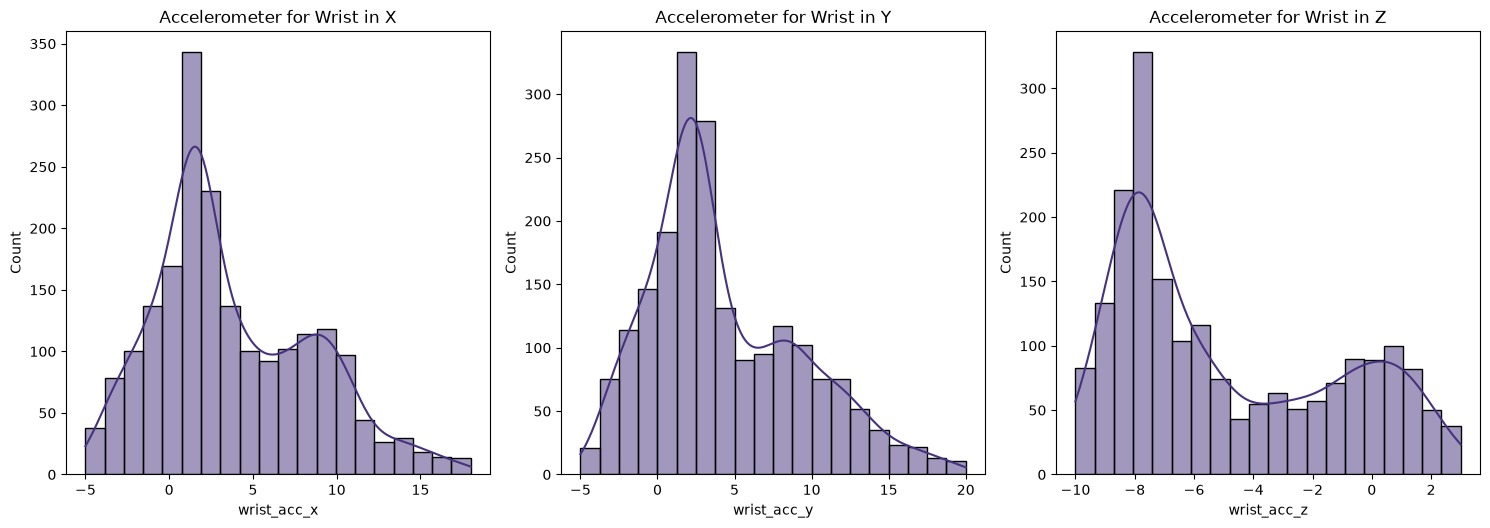

In [222]:
# Distribution of Accelemeter for Wrist (X,Y,Z)
plt.figure(figsize=(15,20))

# Wrist Accelerometer X
plt.subplot(4,3,1)
sns.histplot(sensor_df["wrist_acc_x"], kde=True, bins=20)
plt.title("Accelerometer for Wrist in X")
plt.xlabel("wrist_acc_x")

# Wrist Accelerometer Y
plt.subplot(4,3,2)
sns.histplot(sensor_df["wrist_acc_y"], kde=True, bins=20)
plt.title("Accelerometer for Wrist in Y")
plt.xlabel("wrist_acc_y")

# Wrist Accelerometer Z
plt.subplot(4,3,3)
sns.histplot(sensor_df["wrist_acc_z"], kde=True, bins=20)
plt.title("Accelerometer for Wrist in Z")
plt.xlabel("wrist_acc_z")

plt.tight_layout()
plt.show()

### Wrist Accelerometer X
 *  Highest peak around 1–2, with a smaller second peak around 8–10 (bimodal). Right-skewed with a long tail toward higher values

### Wrist Accelerometer Y
 * Highest peak around 2–3, with a smaller second peak around 8 (bimodal). Right-skewed with a long tail toward higher values.
### Wrist Accelerometer Z
* Highest peak around −8, with a broader second cluster around −1 to 1 (bimodal). Most values are negative. Slightly right-skewed.

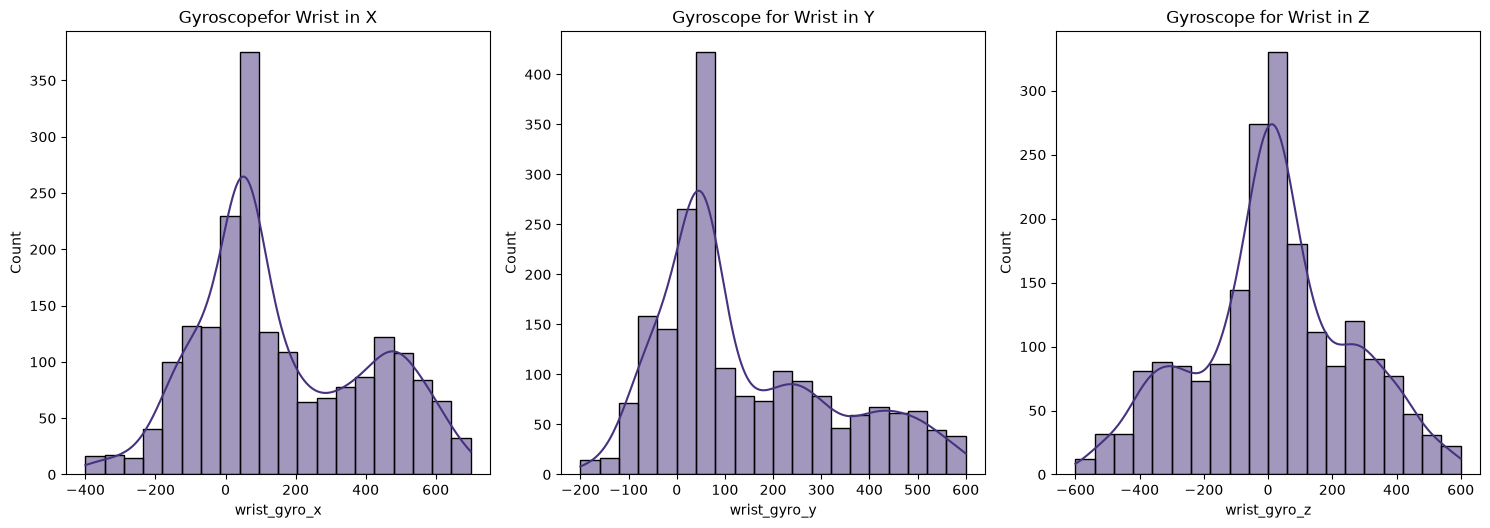

In [223]:
# Distribution of Angular velocit for Wrist (X,Y,Z)
plt.figure(figsize=(15,20))

# Wrist Gyroscope X
plt.subplot(4,3,1)
sns.histplot(sensor_df["wrist_gyro_x"], kde=True, bins=20)
plt.title("Gyroscopefor Wrist in X")
plt.xlabel("wrist_gyro_x")

# Wrist Gyroscope Y
plt.subplot(4,3,2)
sns.histplot(sensor_df["wrist_gyro_y"], kde=True, bins=20)
plt.title("Gyroscope for Wrist in Y")
plt.xlabel("wrist_gyro_y")

# Wrist Gyroscope Z
plt.subplot(4,3,3)
sns.histplot(sensor_df["wrist_gyro_z"], kde=True, bins=20)
plt.title("Gyroscope for Wrist in Z")
plt.xlabel("wrist_gyro_z")

plt.tight_layout()
plt.show()

### Wrist Gyroscope X
* Highest peak around 0–100, with a second peak around 400–500 (bimodal). Slightly right-skewed.
### Wrist Gyroscope Y
* One dominant peak around 0–80, with weak bumps around 250 and 450. Right-skewed.
#### Wrist Gyroscope Z
* Centered around 0, with small side bumps around −300 and +300. Roughly symmetric.




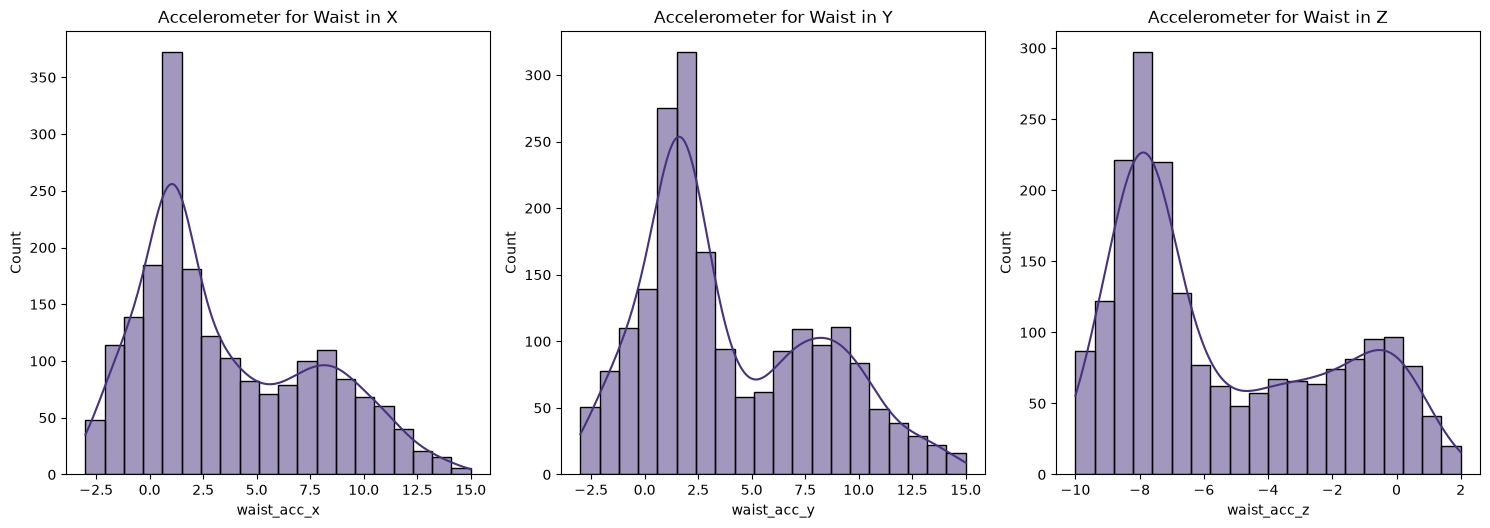

In [224]:
# Distribution of Accelemeter for Wasit (X,Y,Z)
plt.figure(figsize=(15,20))

# Waist Accelerometer X
plt.subplot(4,3,1)
sns.histplot(sensor_df["waist_acc_x"], kde=True, bins=20)
plt.title("Accelerometer for Waist in X")
plt.xlabel("waist_acc_x")

# Waist Accelerometer Y
plt.subplot(4,3,2)
sns.histplot(sensor_df["waist_acc_y"], kde=True, bins=20)
plt.title("Accelerometer for Waist in Y")
plt.xlabel("waist_acc_y")

# Waist Accelerometer Z
plt.subplot(4,3,3)
sns.histplot(sensor_df["waist_acc_z"], kde=True, bins=20)
plt.title("Accelerometer for Waist in Z")
plt.xlabel("waist_acc_z")

plt.tight_layout()
plt.show()

### Waist Accelerometer X
* Highest peak around 1, with a second peak around 8–9 (bimodal). Right-skewed.
### Waist Accelerometer Y
* Highest peak around 2, with a second peak around 8–9 (bimodal). Right-skewed.

### Waist Accelerometer Z
* Highest peak around −8, with a second cluster around −1 to 0 (bimodal). Right-skewed.

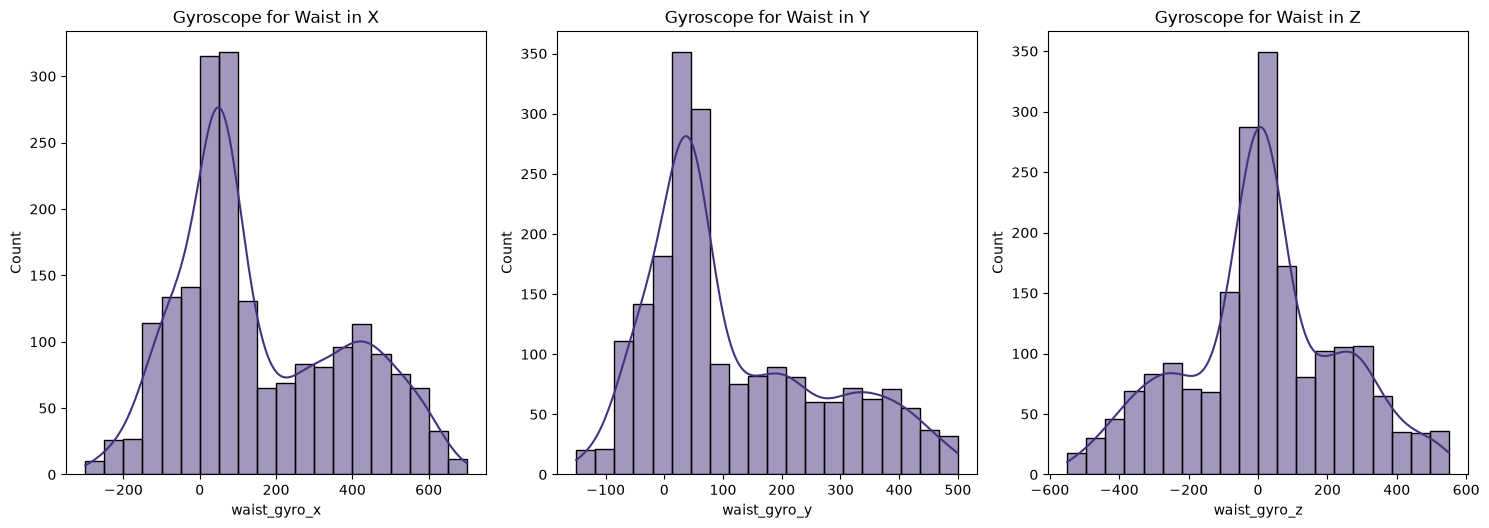

In [225]:
# Distribution of Angular velocit for Waist (X,Y,Z)
plt.figure(figsize=(15,20))

# Waist Gyroscope X
plt.subplot(4,3,1)
sns.histplot(sensor_df["waist_gyro_x"], kde=True, bins=20)
plt.title("Gyroscope for Waist in X")
plt.xlabel("waist_gyro_x")

# Waist Gyroscope Y
plt.subplot(4,3,2)
sns.histplot(sensor_df["waist_gyro_y"], kde=True, bins=20)
plt.title("Gyroscope for Waist in Y")
plt.xlabel("waist_gyro_y")

# Waist Gyroscope Z
plt.subplot(4,3,3)
sns.histplot(sensor_df["waist_gyro_z"], kde=True, bins=20)
plt.title("Gyroscope for Waist in Z")
plt.xlabel("waist_gyro_z")

plt.tight_layout()
plt.show()

### Waist Gyroscope X
* Highest peak around 0–100, with a second peak around 400–450 (bimodal). Slightly right-skewed.
### Waist Gyroscope Y
* One dominant peak around 0–80, with weak bumps around 200 and 350. Right-skewed.
### Waist Gyroscope Z
* Centered around 0, with small side bumps around -250_250. Roughly symmetric.


Text(0.5, 0, 'heart_rate')

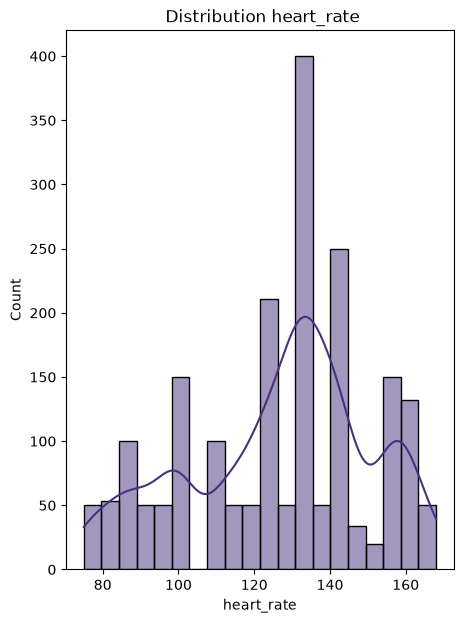

In [226]:
plt.figure(figsize=(5,7))
sns.histplot(sensor_df["heart_rate"], kde=True, bins=20)
plt.title(" Distribution heart_rate")
plt.xlabel("heart_rate")


### Heart Rate

* Most readings are concentrated between 130 and 145 BPM.
* The highest peak appears around 133 BPM.
* Smaller peaks appear around 100, 123, 143 and 157–160 BPM.
* The distribution appears multimodal, with multiple peaks

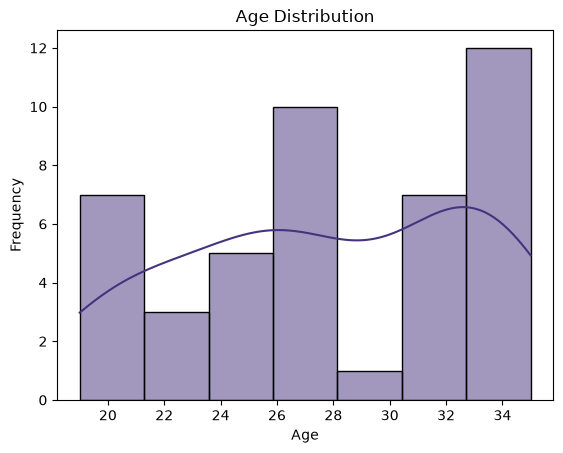

In [227]:
# Visualize Age distribution
sns.histplot(data=subject_df, x='Age', kde=True)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

 ### Age
 * No clear shape. Highest counts around 33–35 and 26–28.

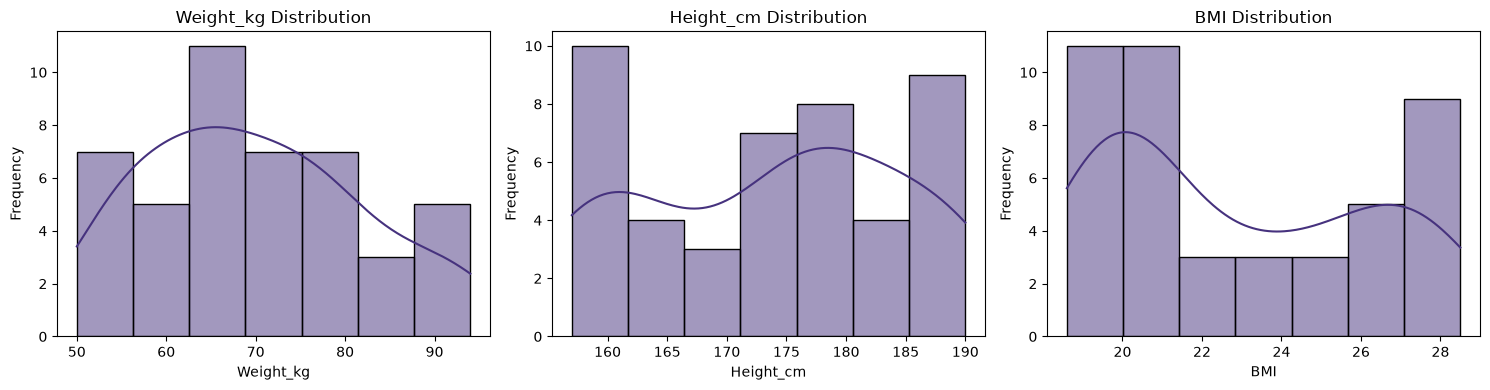

In [228]:
# Plot Histograms for Weight, Height, and BMI
features = ['Weight_kg', 'Height_cm', 'BMI']

plt.figure(figsize=(15, 4))

for i, feature in enumerate(features):
    plt.subplot(1, 3, i + 1)
    sns.histplot(data=subject_df, x=feature, kde=True)
    plt.title(f'{feature} Distribution')
    plt.xlabel(feature)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

##### Weight: Peak around 62–70 kg, slightly right-skewed.
##### Height: Two groups, one around 160–161 cm and one around 175–190 cm.
##### BMI: Main group around 19–21.5, with a smaller group around 27–28.5. Right-skewed.

 ### Boxplot

* Used to visualize the spread of numerical sensor features and identify potential outliers.

<Axes: >

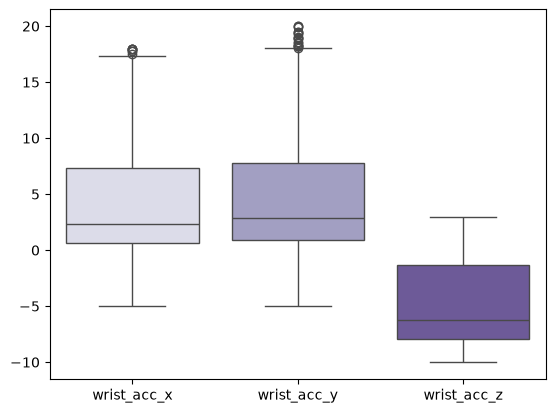

In [229]:
# Visualize outliers using Boxplots

Wrist_Acc = ["wrist_acc_x", "wrist_acc_y", "wrist_acc_z"]
sns.boxplot(sensor_df[Wrist_Acc], palette="Purples")

* X: Median around 2  with  A few outliers at the upper end.
* Y: Median around 3  with  Several outliers at the upper end.
* Z: Median around −6 with No outliers.

<Axes: >

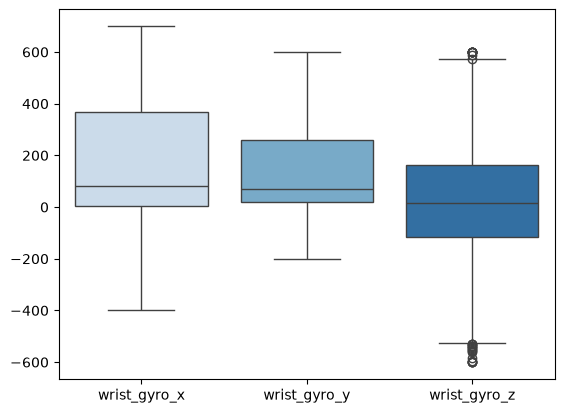

In [230]:

Wrist_Gyro = [
    
    "wrist_gyro_x", "wrist_gyro_y", "wrist_gyro_z"
]
sns.boxplot(sensor_df[Wrist_Gyro], palette="Blues")

* X: Median around 90, No outliers.
* Y: Median around 70, No outliers.
* Z: Median around 10, outliers on both ends.

<Axes: >

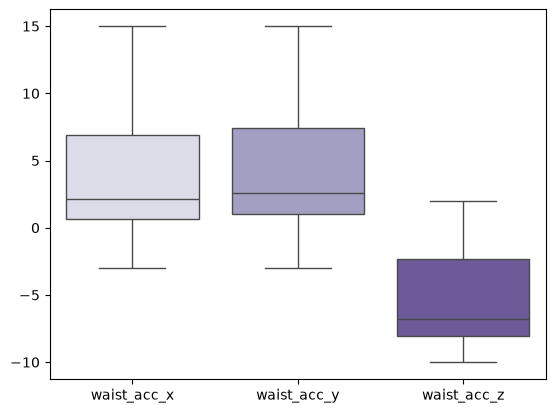

In [231]:
Waist_Acc=["waist_acc_x", "waist_acc_y", "waist_acc_z"]
sns.boxplot(sensor_df[Waist_Acc], palette="Purples")

* X: Median around 2,No outliers.
* Y: Median around 2.5, No outliers.
* Z: Median around −8, No outliers.


<Axes: >

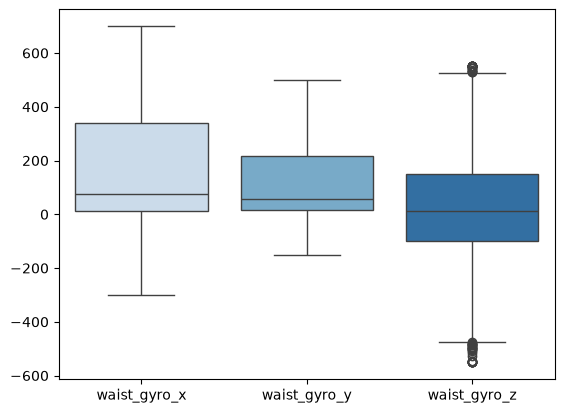

In [232]:
Waist_Gyro=["waist_gyro_x", "waist_gyro_y", "waist_gyro_z"]
sns.boxplot(sensor_df[Waist_Gyro], palette="Blues")

* X: Median around 80 ,No outliers.
* Y: Median around 70 , No outliers.
* Z: Median around 10, Outliers on both ends.

<Axes: ylabel='heart_rate'>

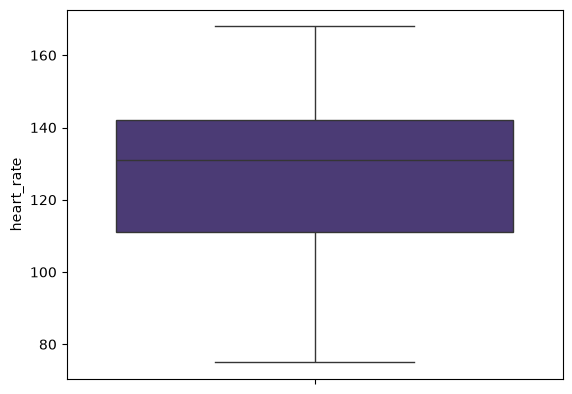

In [233]:
sns.boxplot(sensor_df["heart_rate"])

* Heart Rate:Median around 135 BPM with No outliers.

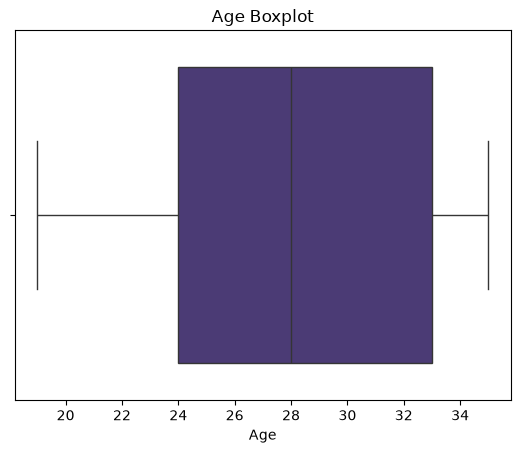

In [234]:
# Visualize Age spread and potential outliers
sns.boxplot(data=subject_df, x='Age')

plt.title('Age Boxplot')
plt.xlabel('Age')
plt.show()

* Age: Median  28 Age,No outliers.

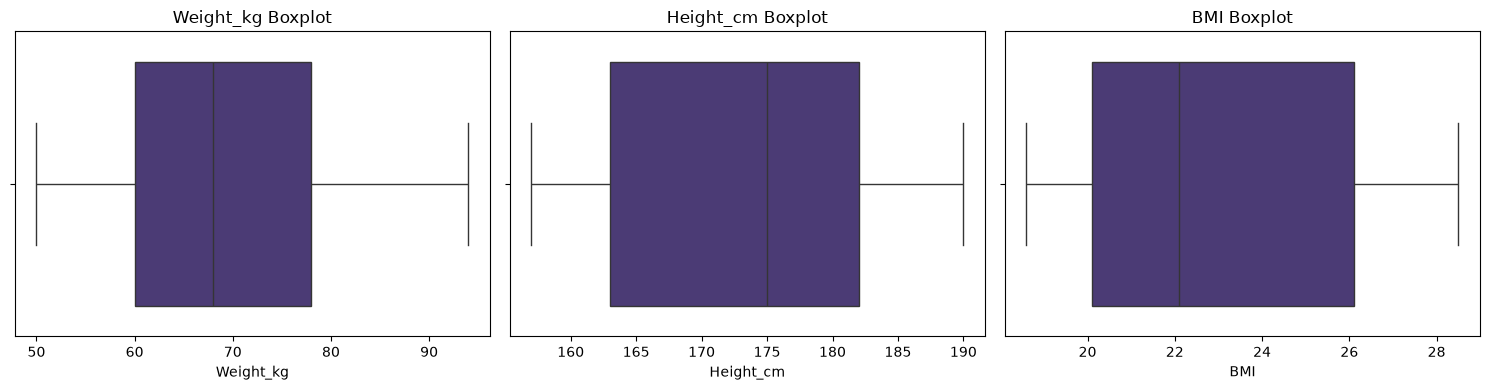

In [235]:
# Plot Boxplots for Weight, Height, and BMI
plt.figure(figsize=(15, 4))

for i, feature in enumerate(features):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(data=subject_df, x=feature)
    plt.title(f'{feature} Boxplot')
    plt.xlabel(feature)

plt.tight_layout()
plt.show()

* Weight: Median 68 kg, No outliers.
* Height: Median 175 cm,No outliers.
* BMI: Median 22,No outliers.

### Countplot

* Used to visualize the frequency of each category and understand the distribution of categorical data.

In [236]:
# Count the number of records for each activity
sensor_df['activity_label'].value_counts()

activity_label
Stretching    353
Running       350
Squatting     334
Sit-ups       332
Jumping       320
Push-ups      311
Name: count, dtype: int64

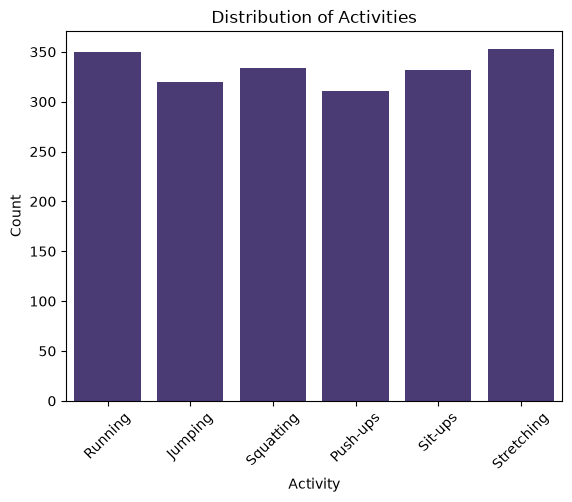

In [237]:
# Visualize the distribution of activities
sns.countplot(data=sensor_df, x='activity_label')

plt.title('Distribution of Activities')
plt.xlabel('Activity')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

* The activities are almost balanced, with about 310–355 records each.
* Some participants have fewer sensor readings than others across activities.

In [238]:
# Count the number of subjects in each category
print(subject_df['Gender'].value_counts())

print(subject_df['Fitness_Level'].value_counts())

Gender
Male      32
Female    13
Name: count, dtype: int64
Fitness_Level
Beginner        18
Advanced        14
Intermediate    13
Name: count, dtype: int64


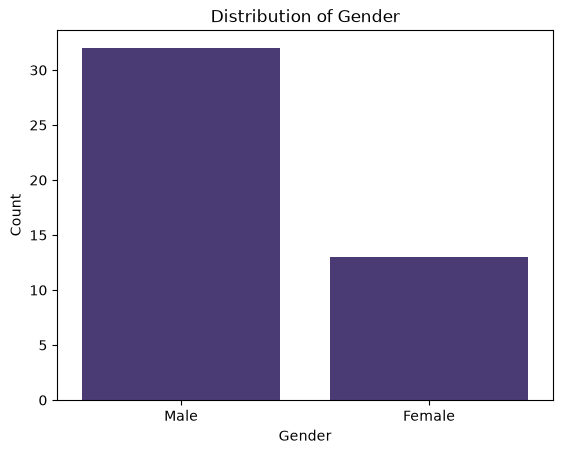

In [239]:
# Visualize the distribution of Gender
sns.countplot(data=subject_df, x='Gender')

plt.title('Distribution of Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

* Males are more than females (32 vs 13)

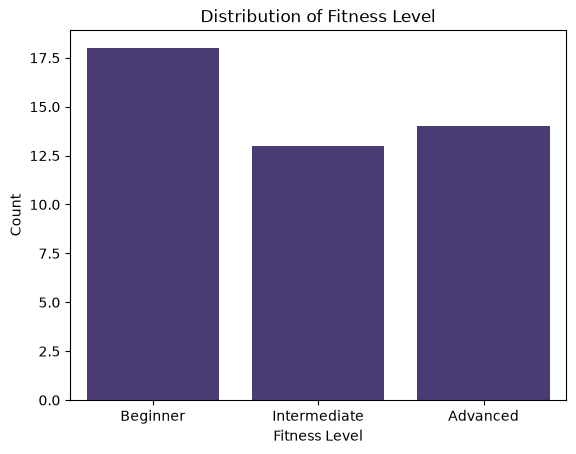

In [240]:
# Visualize the distribution of Fitness Level
sns.countplot(data=subject_df, x='Fitness_Level')

plt.title('Distribution of Fitness Level')
plt.xlabel('Fitness Level')
plt.ylabel('Count')
plt.show()

* Fitness levels are almost balanced, with about 13–18 subjects each.

### 5.2 Bivariate Analysis

<Axes: xlabel='activity_label', ylabel='heart_rate'>

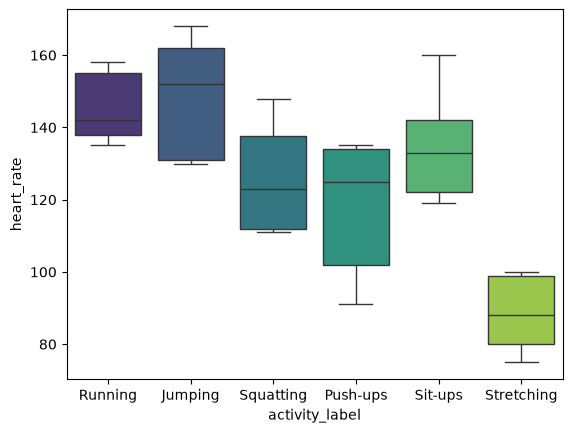

In [241]:
sns.boxplot(
    data=sensor_df,
    x='activity_label',
    y='heart_rate',
    hue='activity_label',
    palette='viridis',
    legend=False
)


* Highest: Jumping recorded the highest heart rate was approximately 152 BPM..
* Lowest: Stretching recorded the lowest heart rate was approximately 87 BPM..
* Variation: Heart rate distributions showed clear differences across activities.
* Outliers: No significant outliers were observed.

In [242]:
# Calculate correlations between numeric sensor features
correlation = sensor_df.drop(
    columns=['subject_id', 'activity_label',"timestamp"]
).corr()

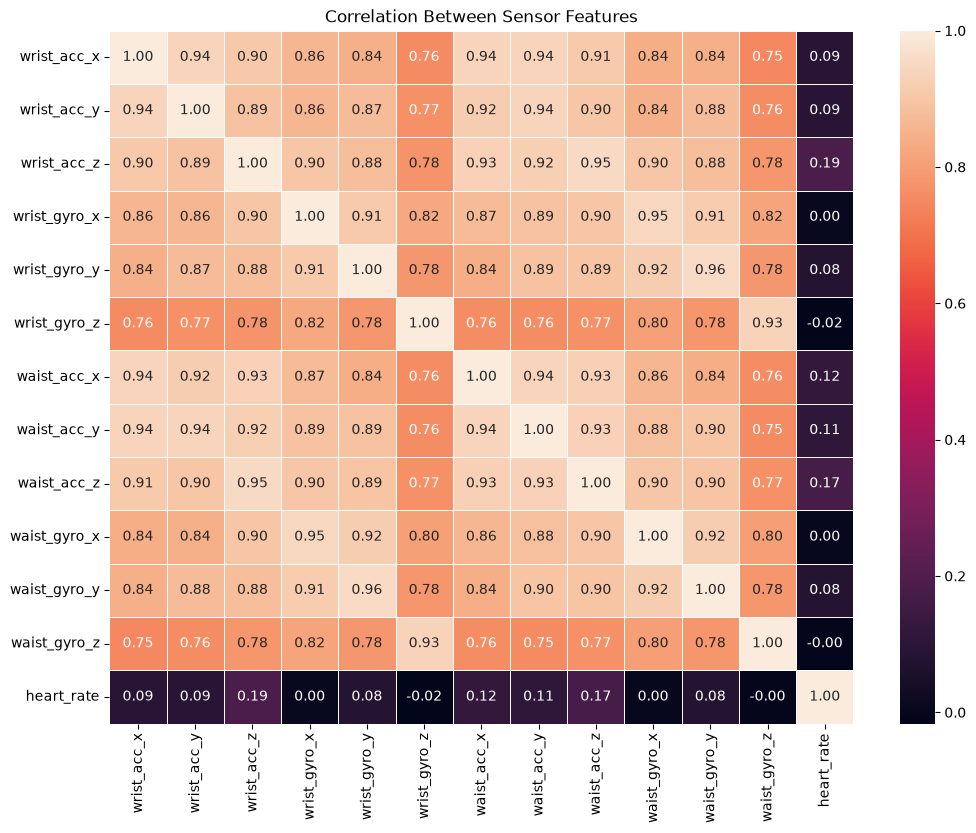

In [243]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap='rocket',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Between Sensor Features')
plt.show()

Correlation Between Sensor Features
* Sensor features are strongly positively correlated (about 0.75–0.96), even wrist with waist and accelerometer with gyroscope. They carry similar information .
* Heart rate has weak correlations with all sensor features (below 0.2),indicating that it may provide additional information rather than duplicating the movement sensor readings.

### Line plot for Accelerometer and Gyroscope(waist,wrist ,X,Y,Z)&Activities


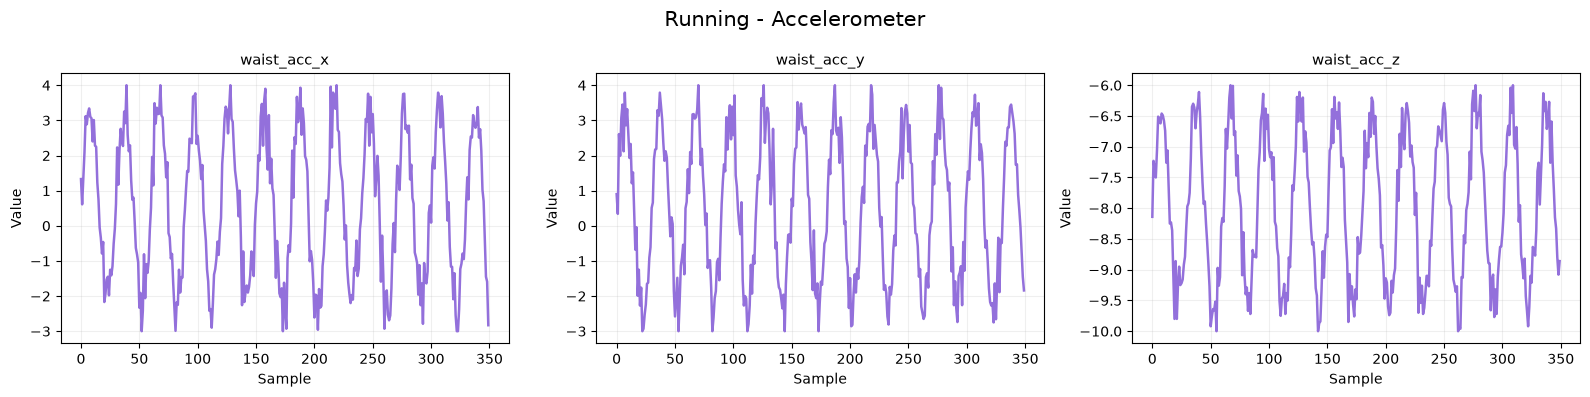

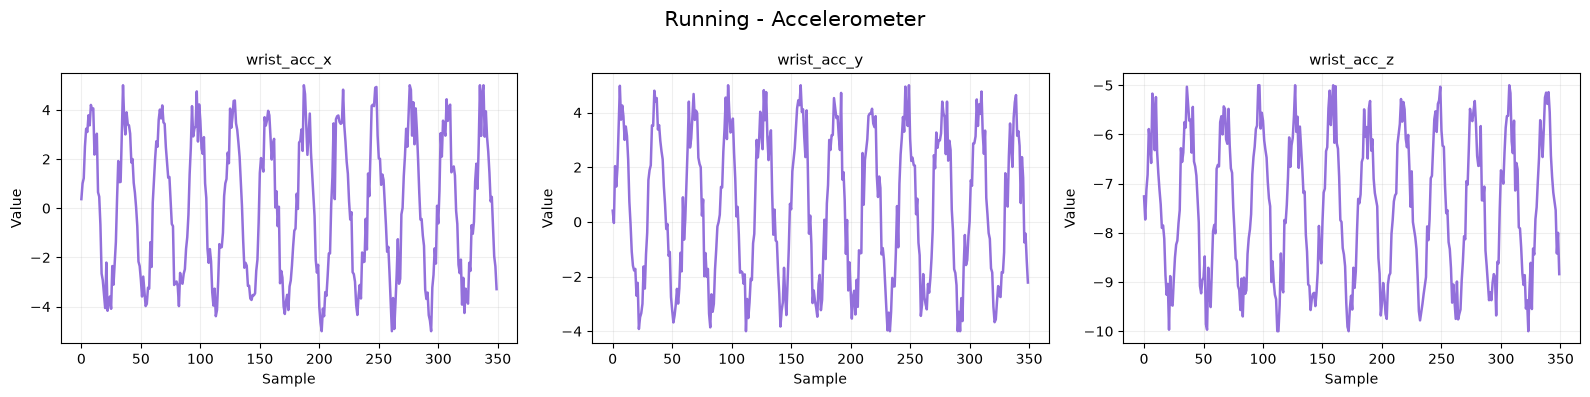

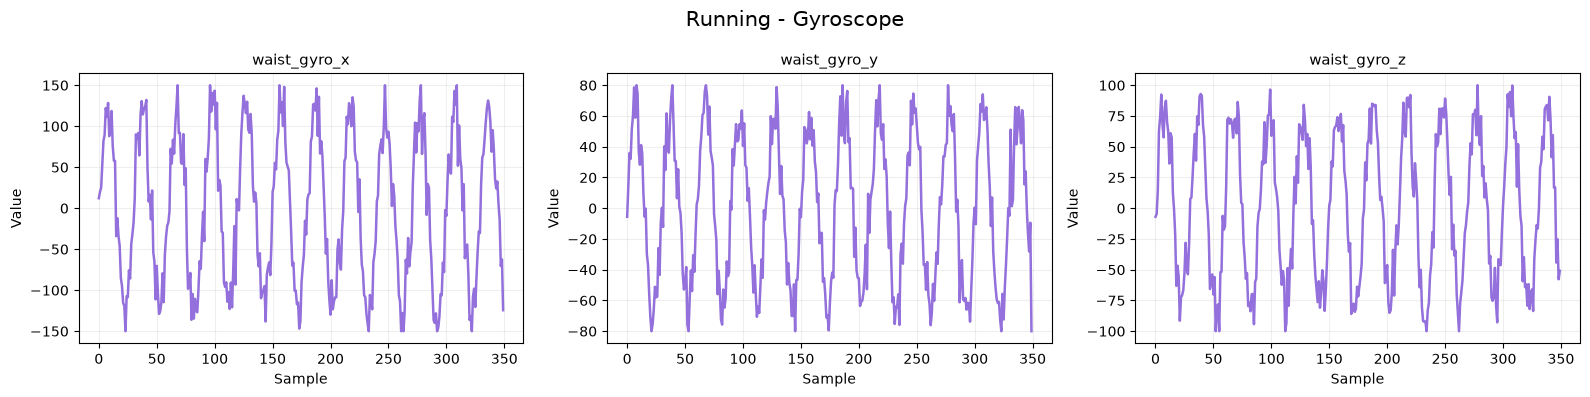

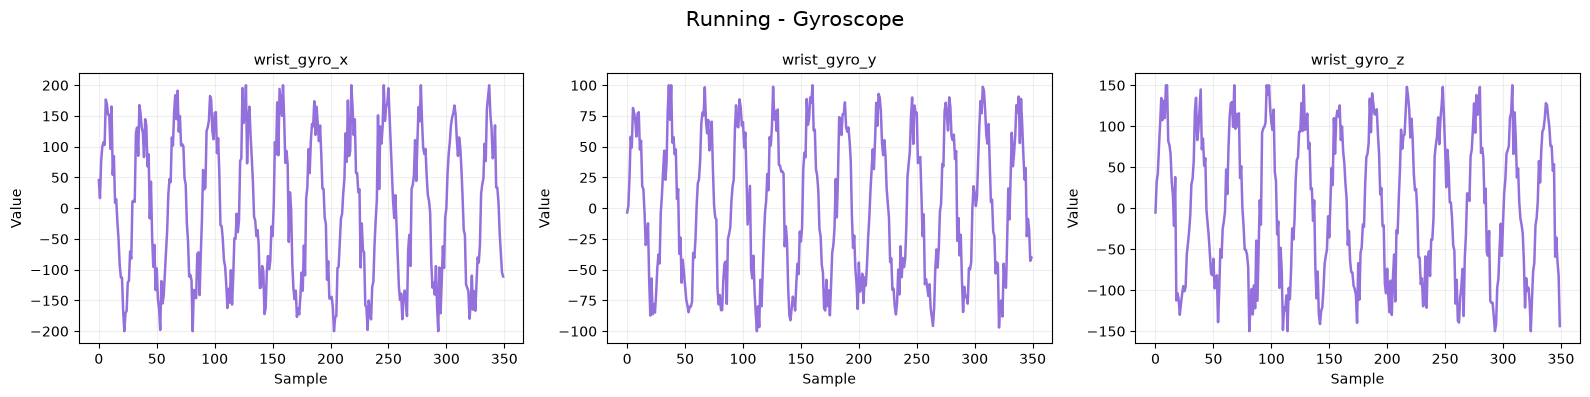

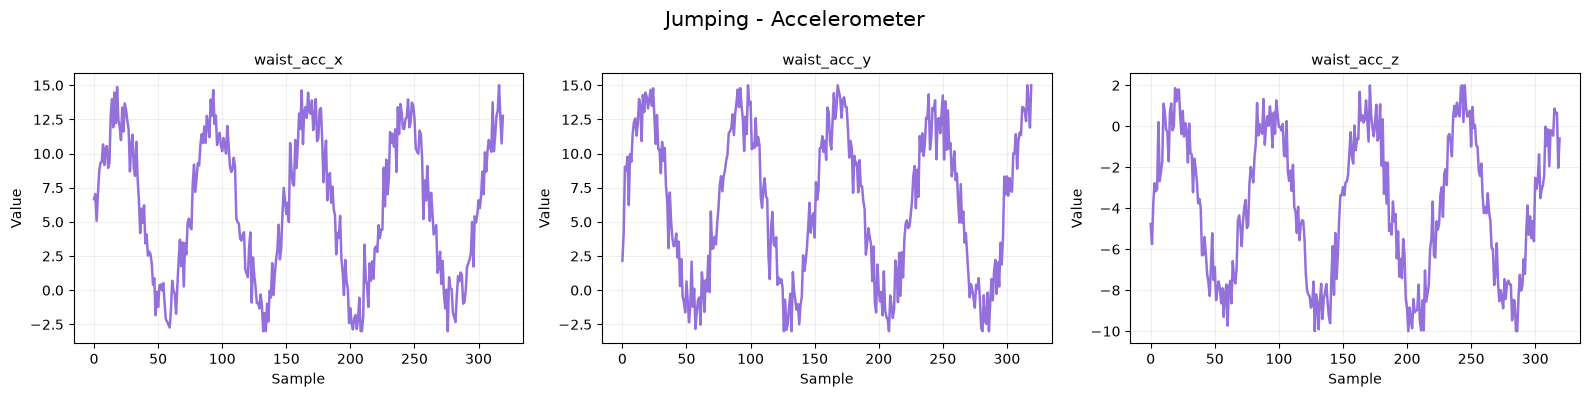

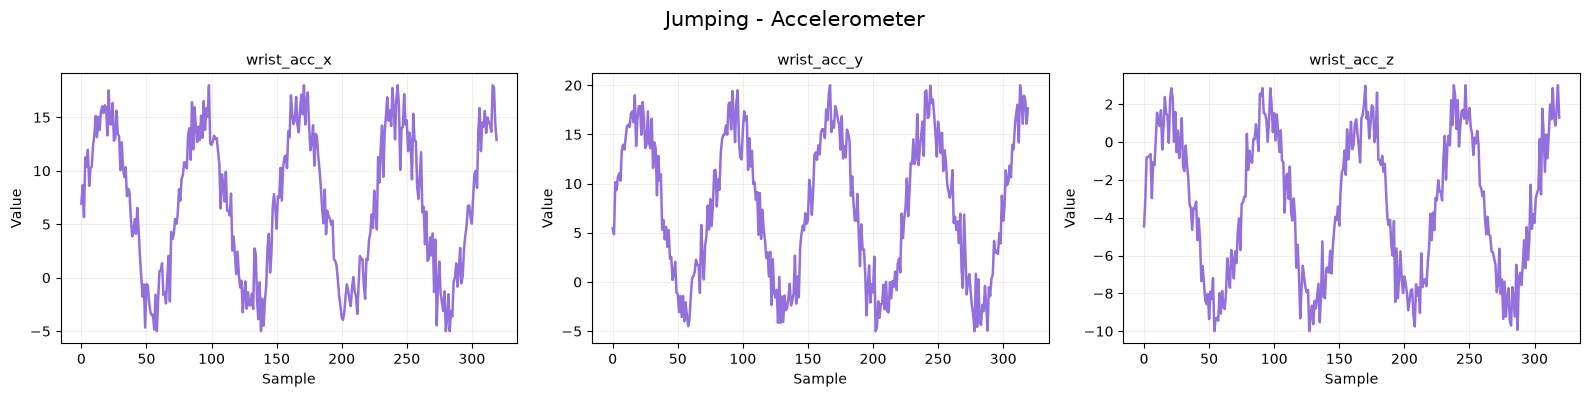

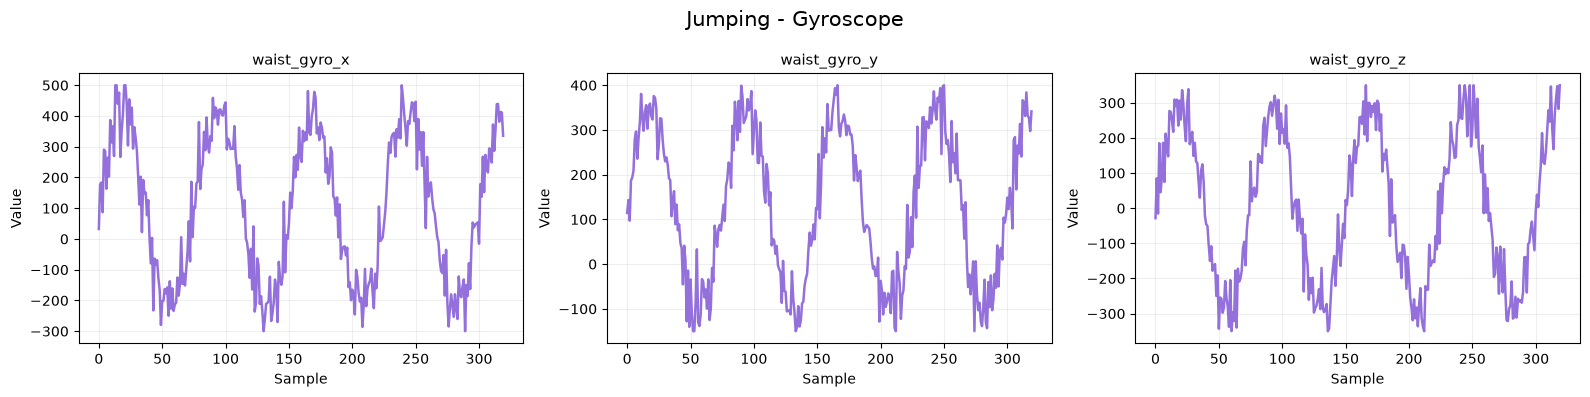

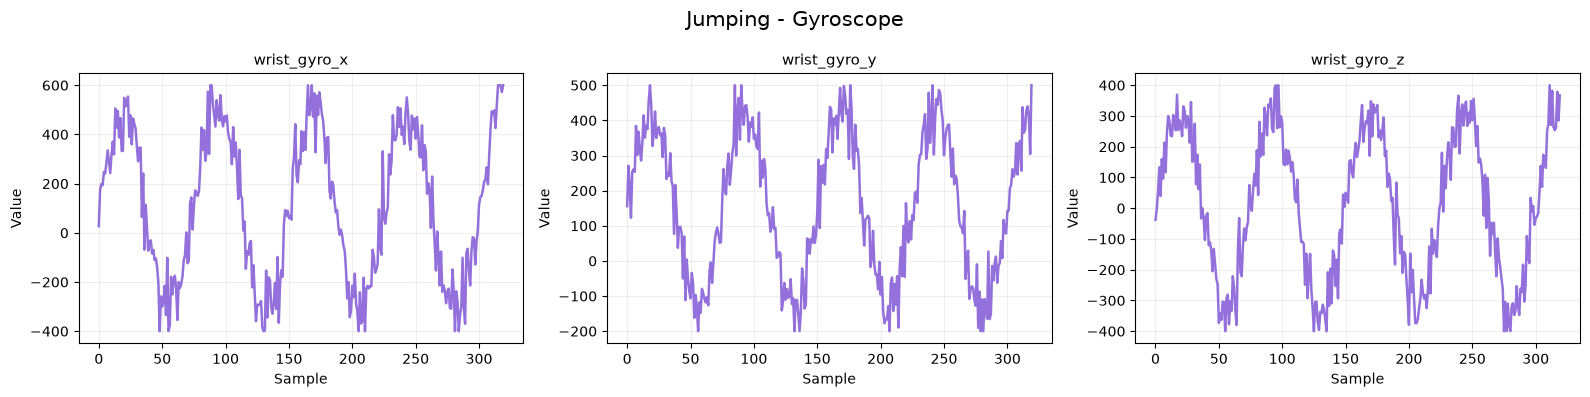

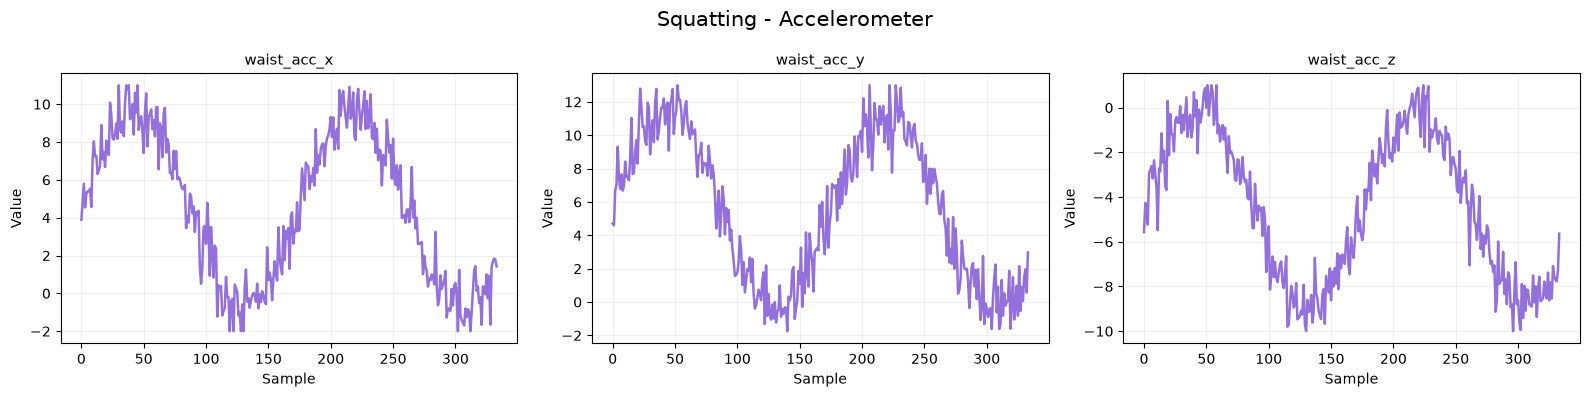

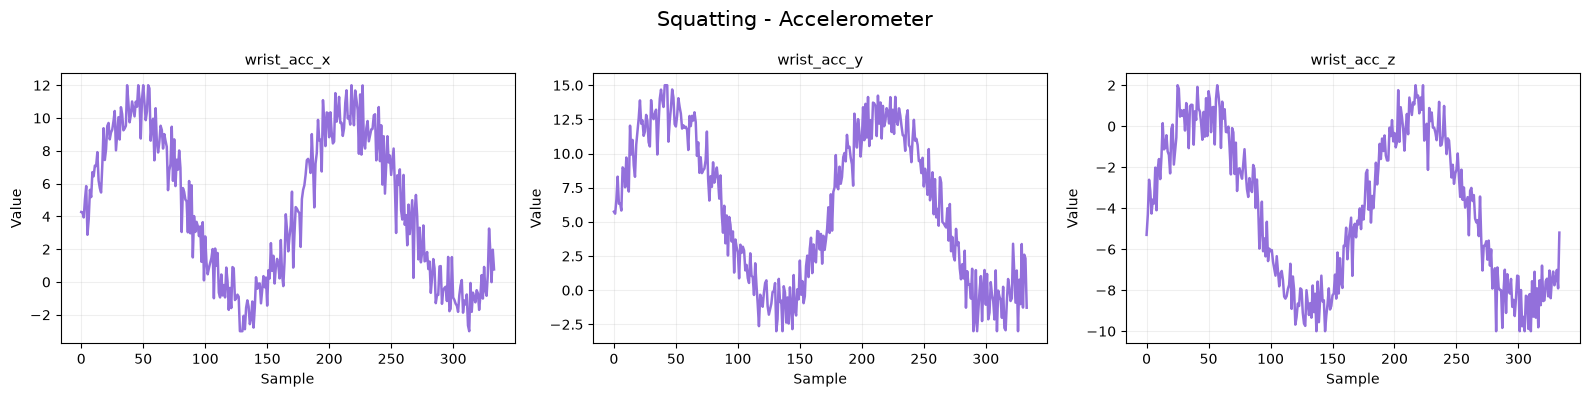

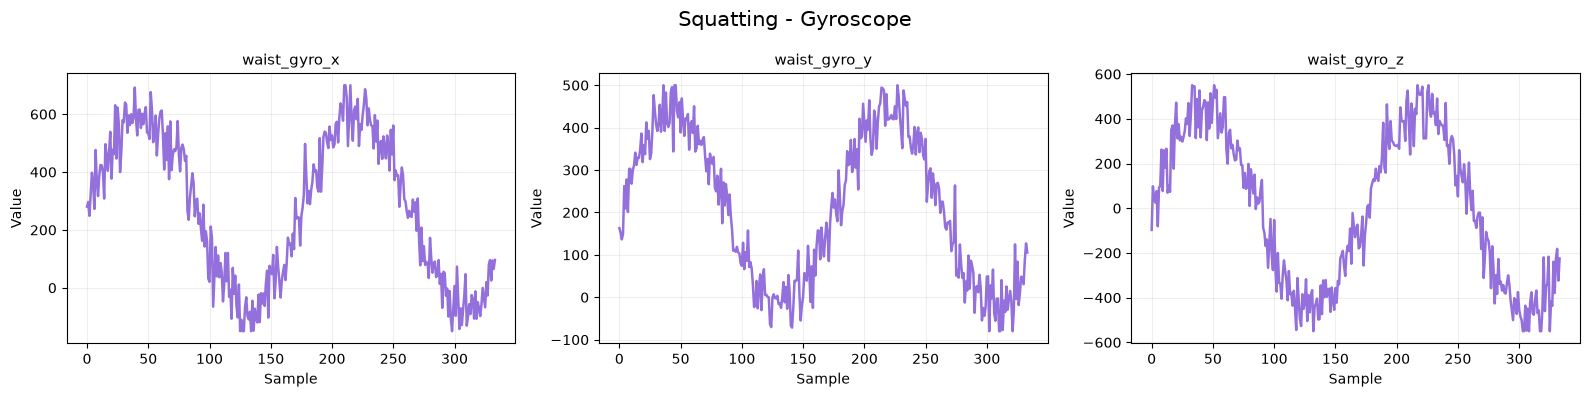

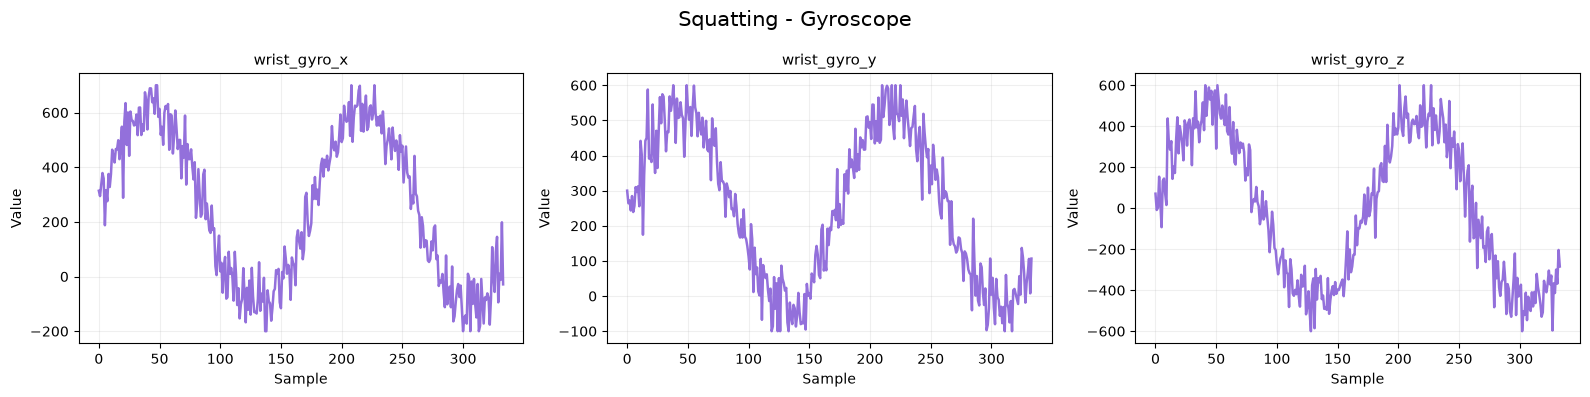

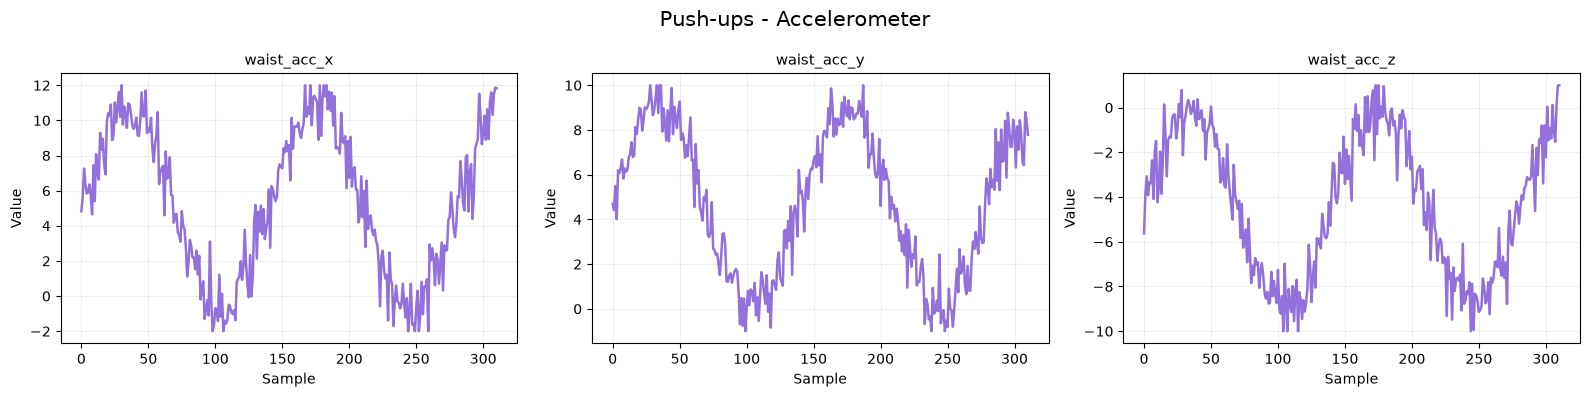

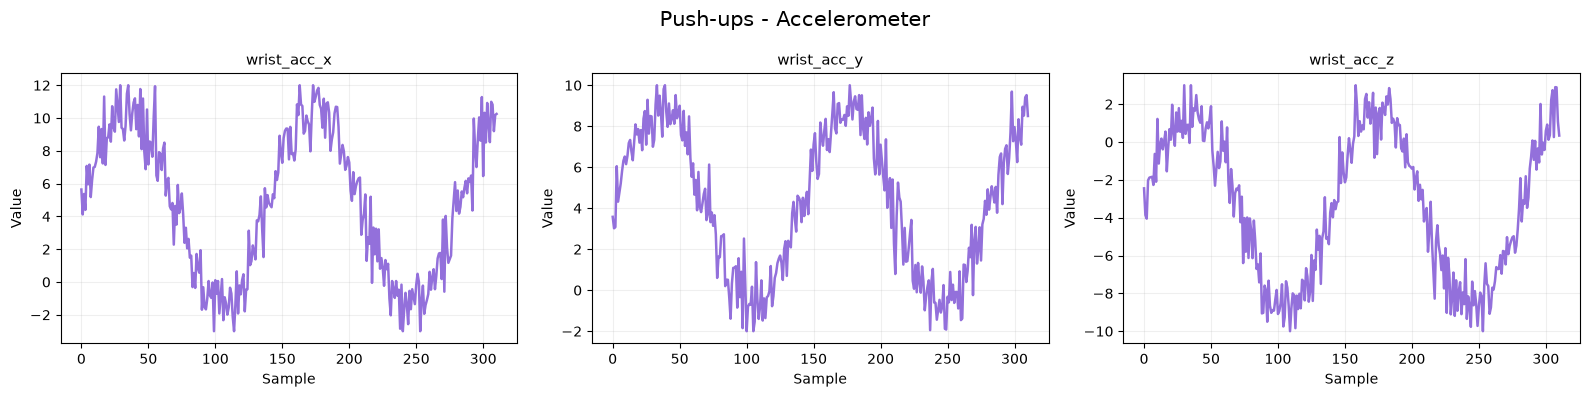

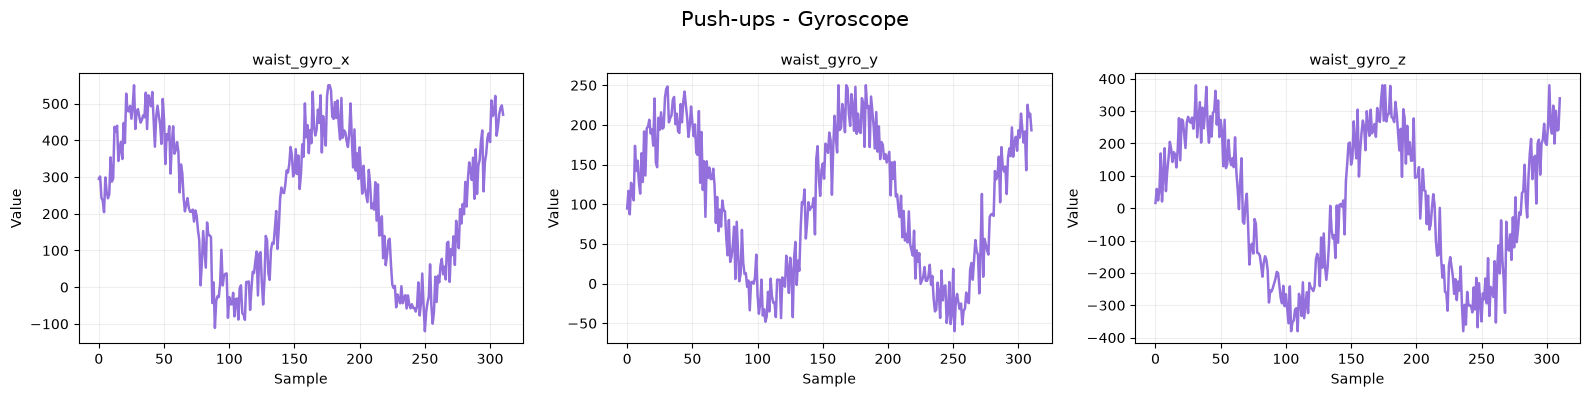

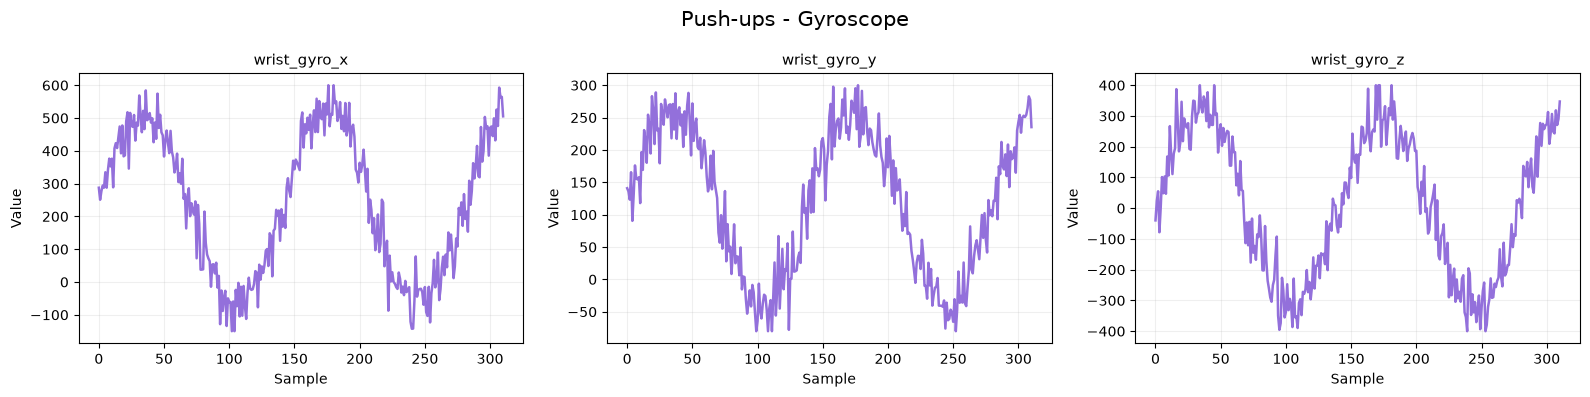

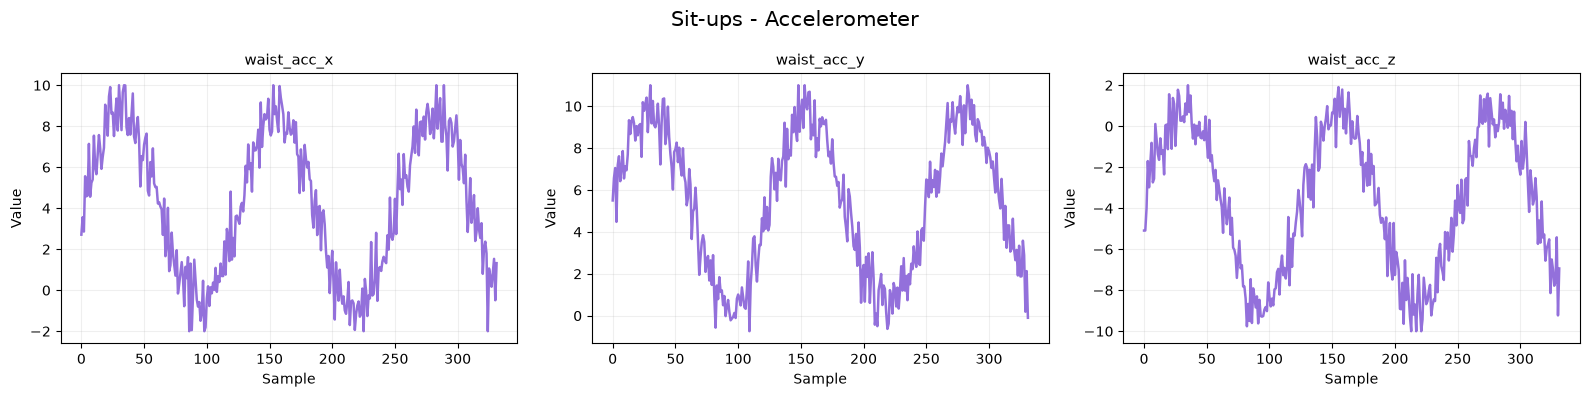

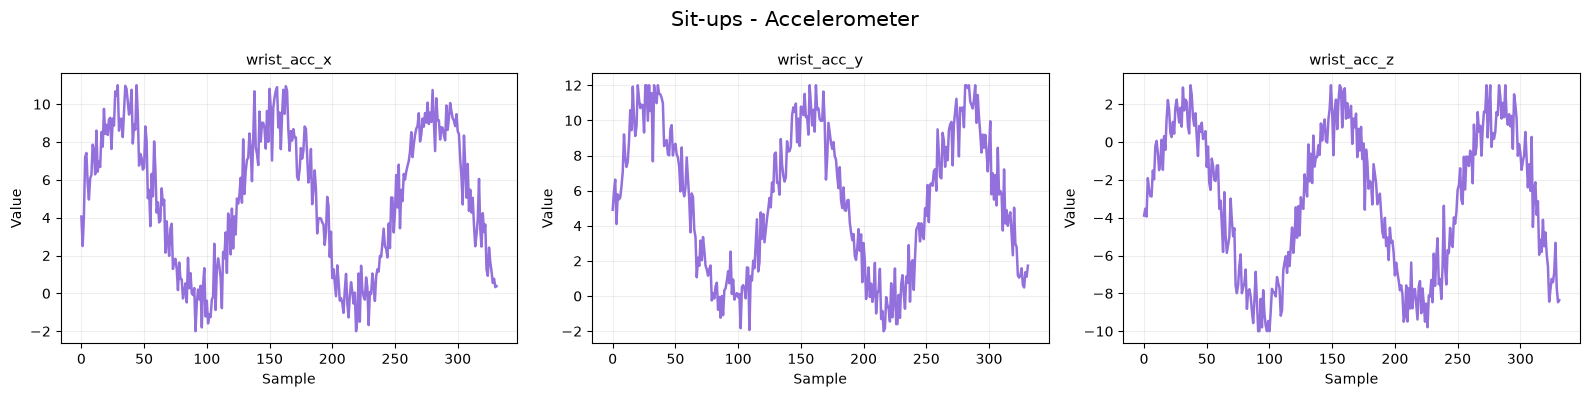

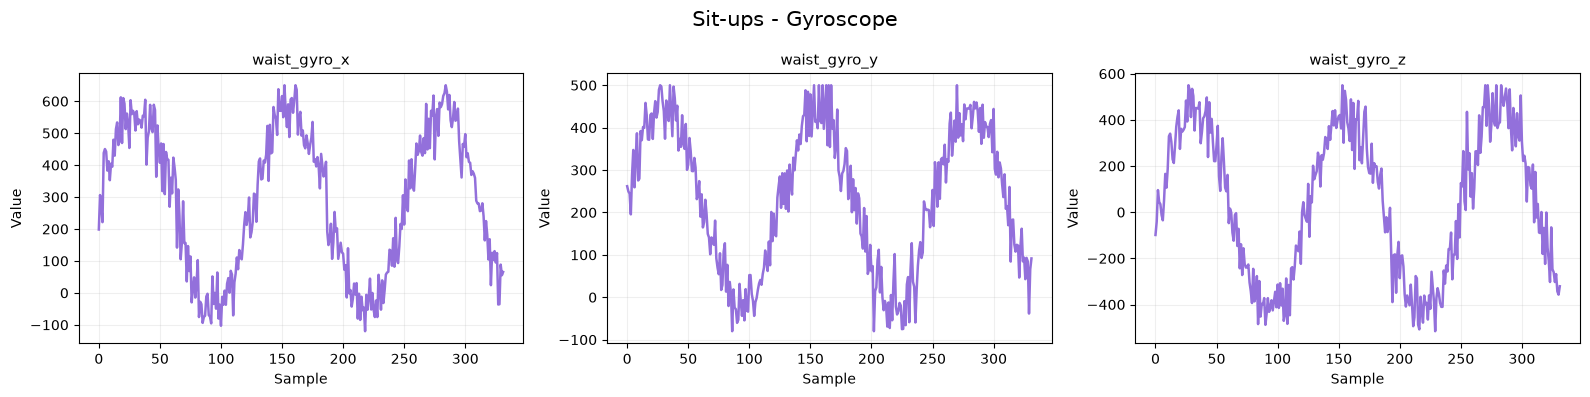

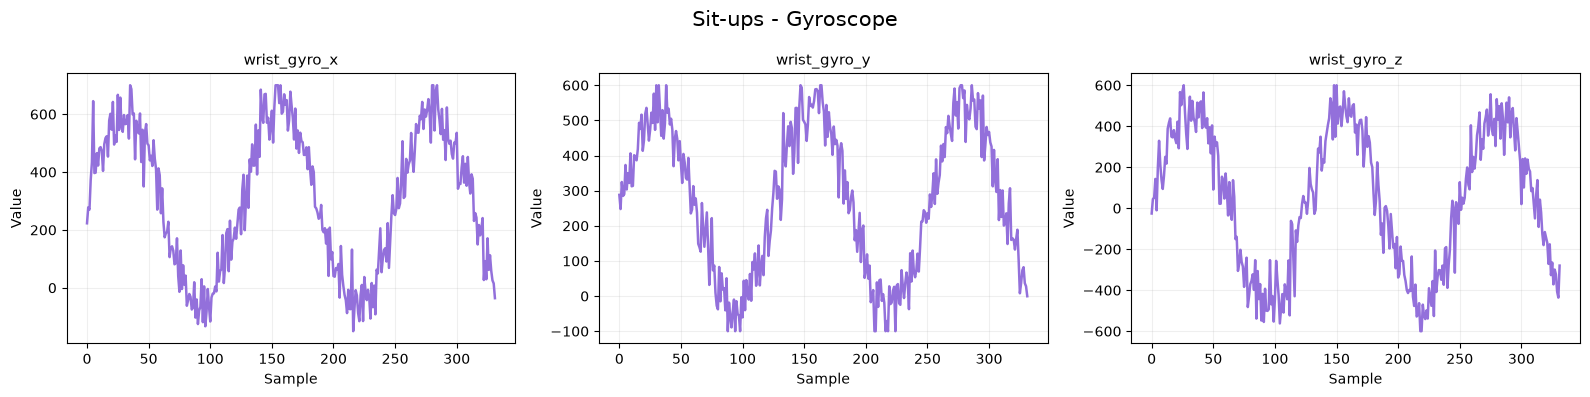

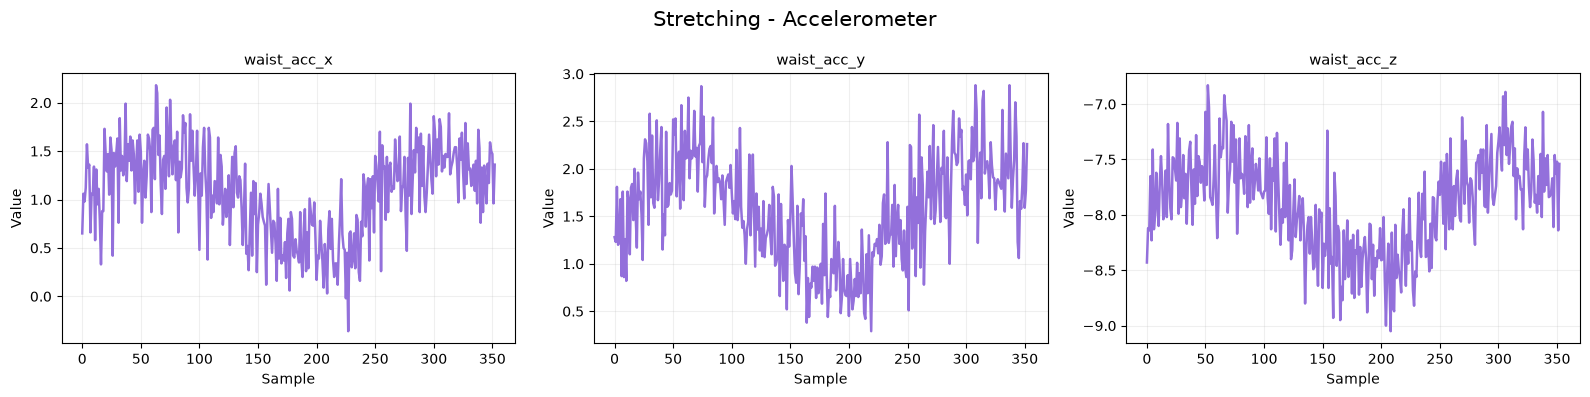

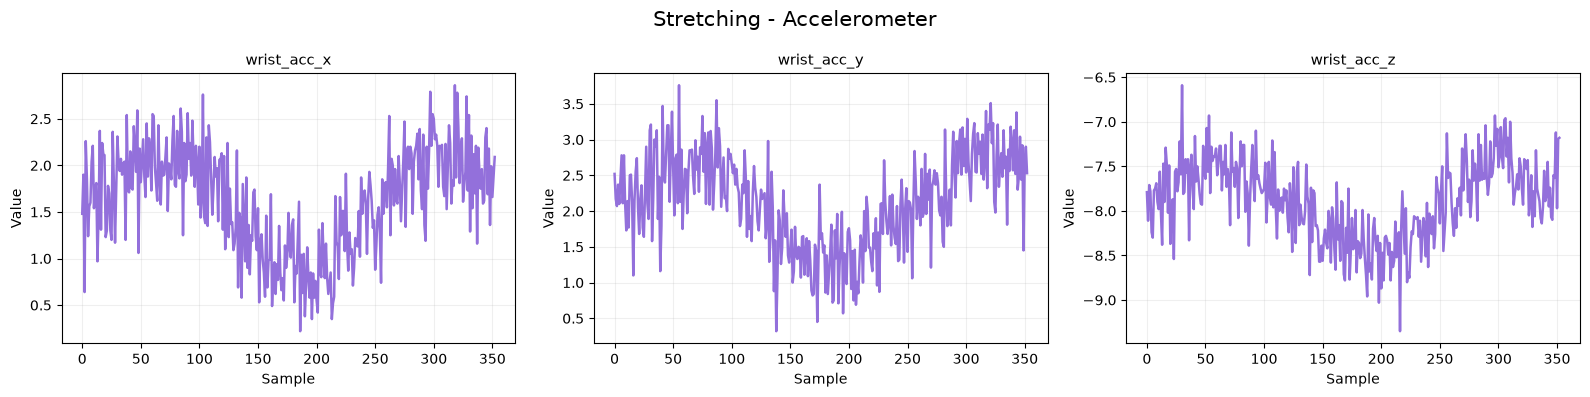

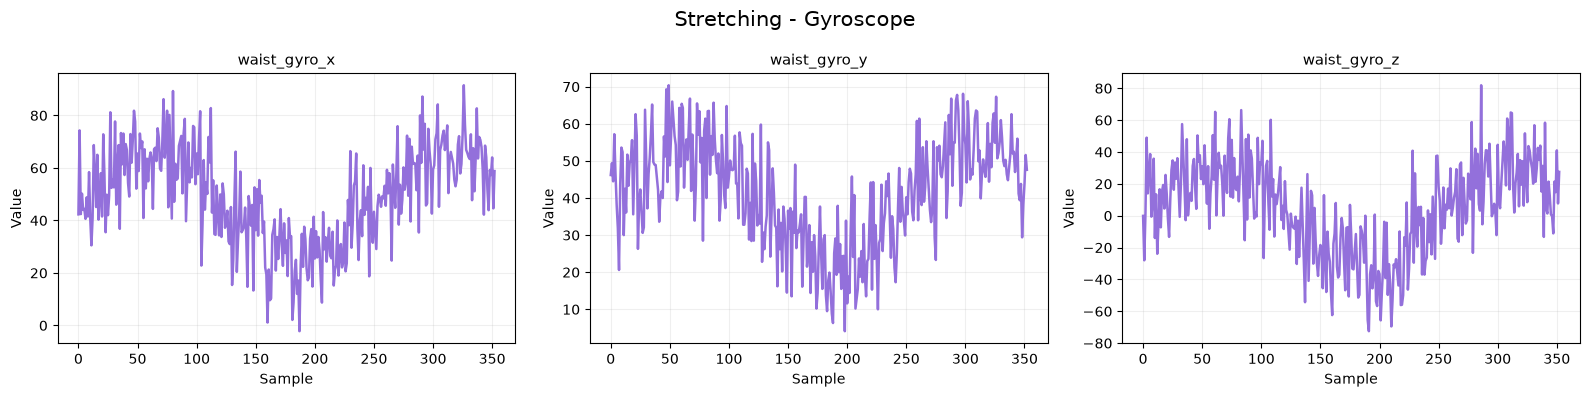

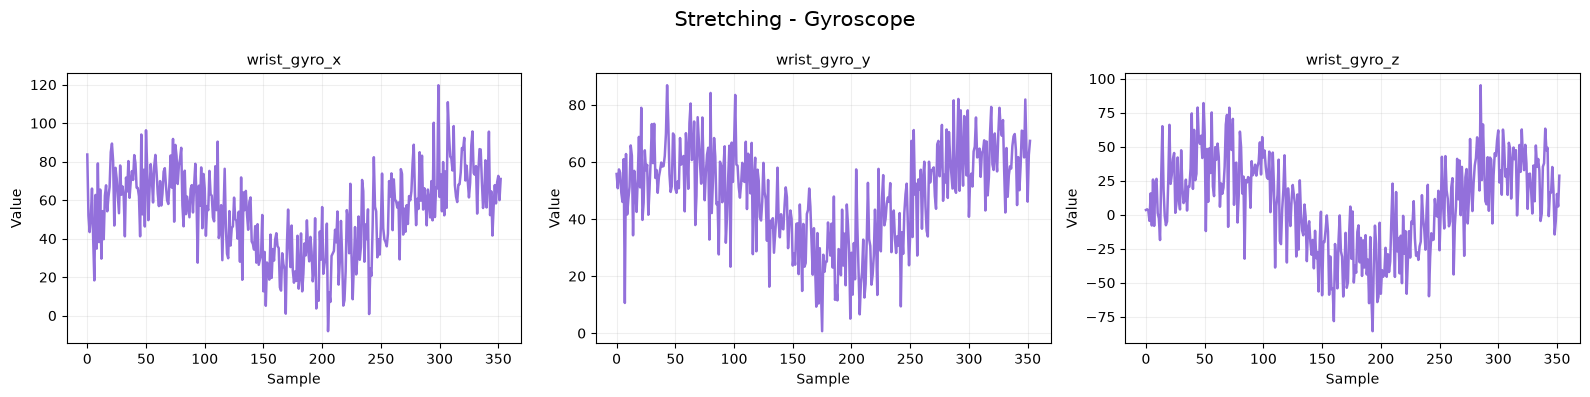

In [244]:

import matplotlib.pyplot as plt

sensors = {
    'Accelerometer': [
        'waist_acc_x', 'waist_acc_y', 'waist_acc_z',
        'wrist_acc_x', 'wrist_acc_y', 'wrist_acc_z'
    ],
    'Gyroscope': [
        'waist_gyro_x', 'waist_gyro_y', 'waist_gyro_z',
        'wrist_gyro_x', 'wrist_gyro_y', 'wrist_gyro_z'
    ]
}

activities = sensor_df['activity_label'].unique()

for activity in activities:

    activity_df = sensor_df[
        sensor_df['activity_label'] == activity
    ].reset_index(drop=True)

    for sensor_type, columns in sensors.items():

        for start in range(0, len(columns), 3):

            selected_columns = columns[start:start + 3]

            fig, axes = plt.subplots(1, 3, figsize=(16, 4))

            for ax, col in zip(axes, selected_columns):

                ax.plot(
                    activity_df[col].values,
                    linewidth=1.8,
                    color='mediumpurple'
                )

                ax.set_title(col, fontsize=11)
                ax.set_xlabel('Sample')
                ax.set_ylabel('Value')
                ax.grid(alpha=0.2)

            fig.suptitle(
                f'{activity} - {sensor_type}',
                fontsize=15
            )

            plt.tight_layout()
            plt.show()



## Activity vs Wrist Accelerometer

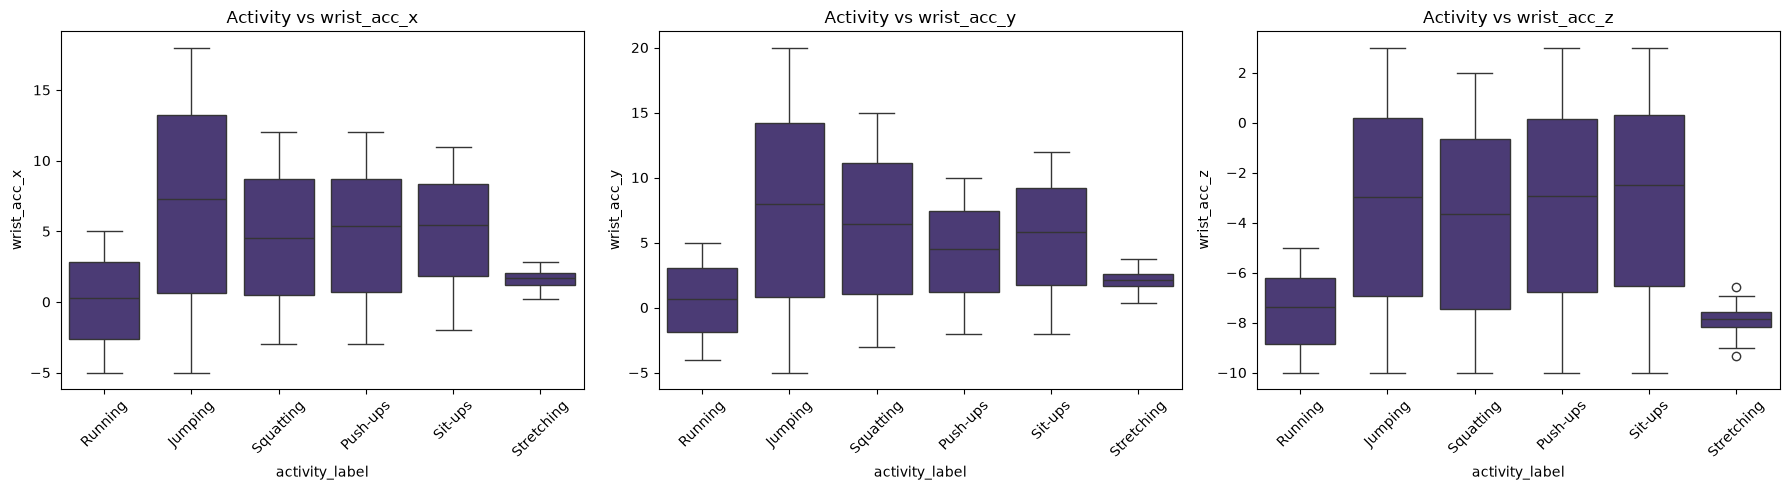

In [245]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

columns = ['wrist_acc_x', 'wrist_acc_y', 'wrist_acc_z']

for ax, col in zip(axes, columns):
    sns.boxplot(
        data=sensor_df,
        x='activity_label',
        y=col,
        ax=ax
    )
    ax.set_title(f'Activity vs {col}')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### How do wrist accelerometer readings vary across different physical activities?

* Jumping showed the highest median values in the X and Y axes, while Sit-ups showed the highest median in the Z-axis. Running recorded the lowest median values across all three axes.


## Activity vs Wrist Gyroscope

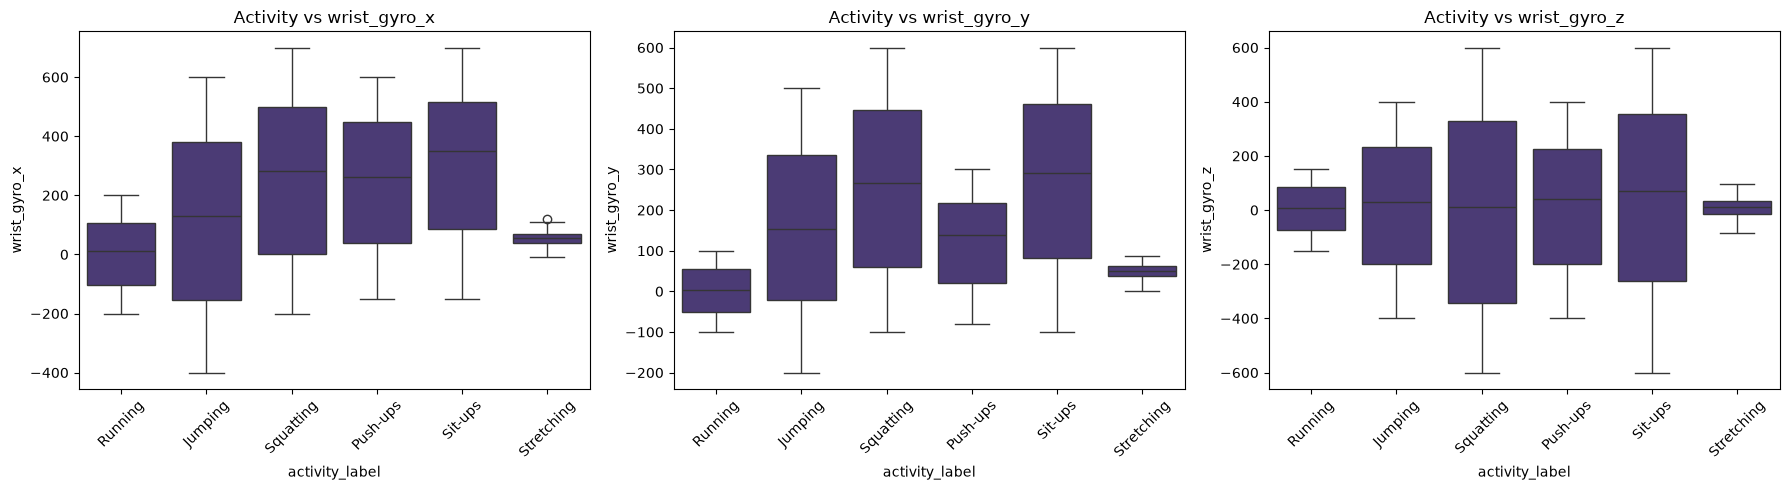

In [246]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

columns = ['wrist_gyro_x', 'wrist_gyro_y', 'wrist_gyro_z']

for ax, col in zip(axes, columns):
    sns.boxplot(
        data=sensor_df,
        x='activity_label',
        y=col,
        ax=ax
    )
    ax.set_title(f'Activity vs {col}')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### How do wrist gyroscope readings vary across different physical activities?
* Sit-ups showed the highest median values across all three axes, while Running recorded the lowest median values across all three axes.


## Activity vs Waist Accelerometer

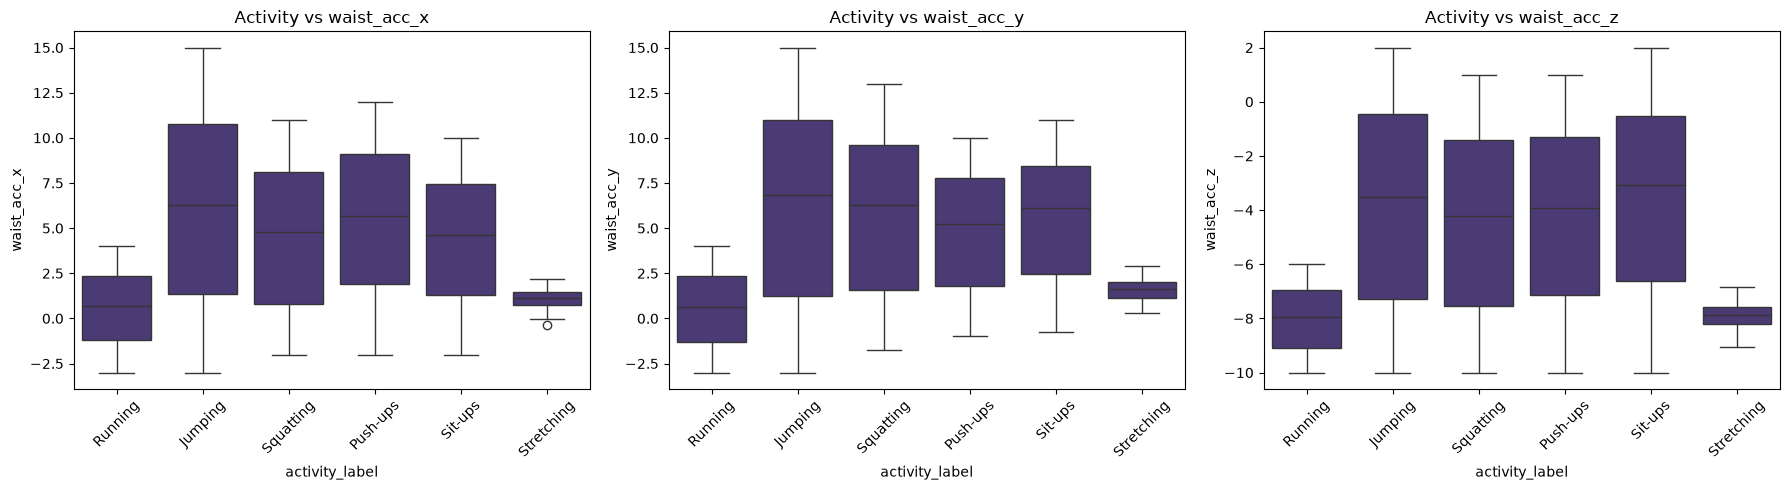

In [247]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

columns = ['waist_acc_x', 'waist_acc_y', 'waist_acc_z']

for ax, col in zip(axes, columns):
    sns.boxplot(
        data=sensor_df,
        x='activity_label',
        y=col,
        ax=ax
    )
    ax.set_title(f'Activity vs {col}')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### How do waist accelerometer readings vary across different physical activities?
* Jumping showed the highest median values in the X and Y axes, while Sit-ups showed the highest median in the Z-axis. Running recorded the lowest median values in the X and Y axes, while Stretching showed the lowest median in the Z-axis.


## Activity vs Waist Gyroscope

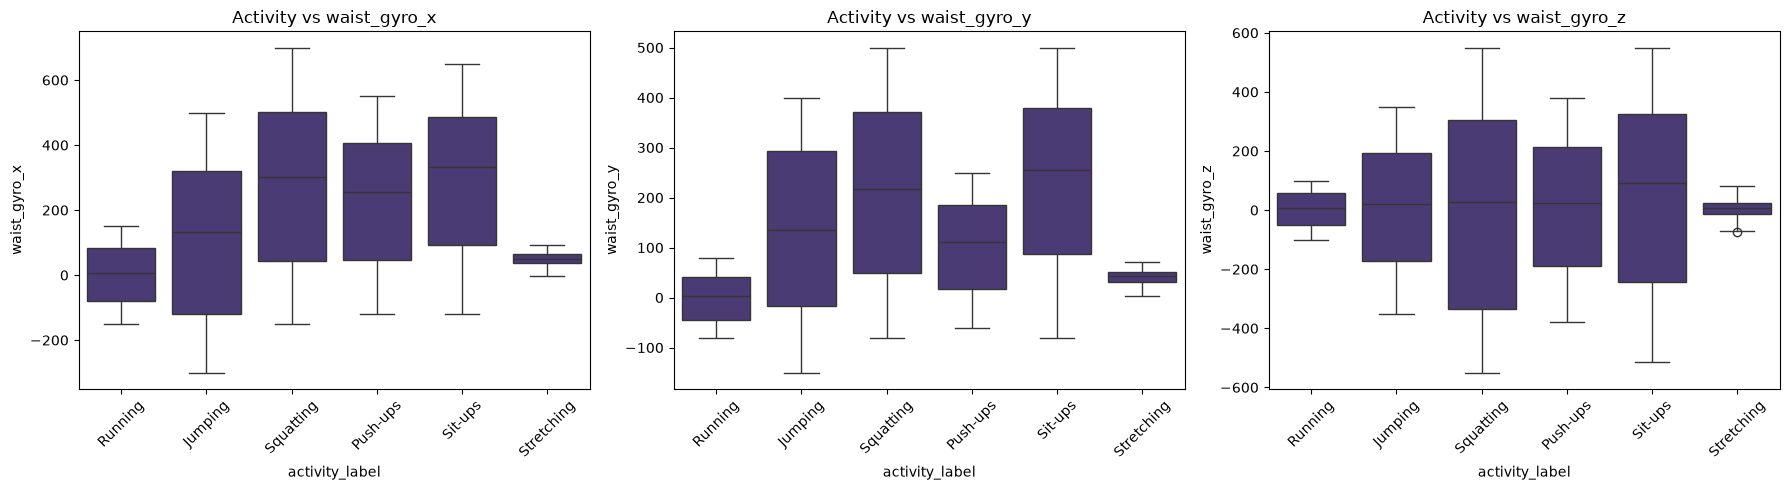

In [248]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

columns = ['waist_gyro_x', 'waist_gyro_y', 'waist_gyro_z']

for ax, col in zip(axes, columns):
    sns.boxplot(
        data=sensor_df,
        x='activity_label',
        y=col,
        ax=ax
    )
    ax.set_title(f'Activity vs {col}')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### How do waist gyroscope readings vary across different physical activities?
* Sit-ups showed the highest median values across all three axes. Running recorded the lowest median values in the X and Y axes, while Squatting showed the lowest median in the Z-axis.


## Gender vs Heart Rate

In [249]:
# Merge subject information with sensor data to analyze heart rate across different subject characteristics..
merged_df = sensor_df.merge(
    subject_df[['Subject_ID', 'Gender']],
    left_on='subject_id',
    right_on='Subject_ID',
    how='left'
)

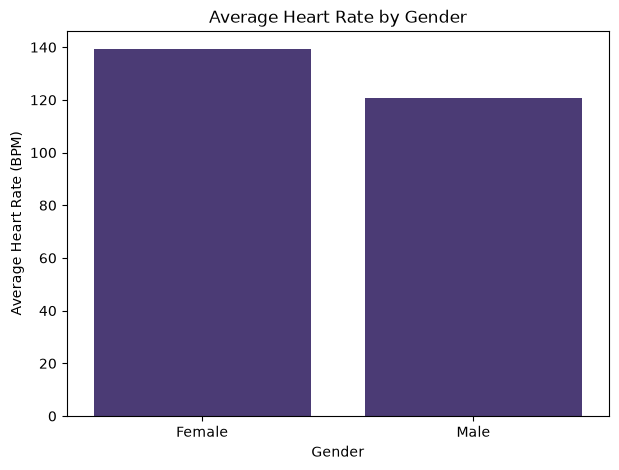

In [250]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=merged_df,
    x='Gender',
    y='heart_rate',
    estimator='mean',
    errorbar=None
)

plt.title('Average Heart Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Heart Rate (BPM)')
plt.show()

### Which gender has a higher average heart rate?
* Females is a higher average heart rate than males, despite having fewer records in the dataset.



**Comparing Average Heart Rate Across Genders Within Each Activity**


In [251]:
merged_df.groupby(['Gender', 'activity_label'])['heart_rate'].mean().unstack()

activity_label,Jumping,Push-ups,Running,Sit-ups,Squatting,Stretching
Gender,,,,,,
Female,149.500000,134.000000,145.6,132.000000,144.428571,97.000000
Male,146.545455,117.103448,142.5,138.232759,117.000000,87.785479


Females showed higher average heart rates in five out of six activities. However, these differences may be influenced by other factors, such as exercise intensity, fitness level, age, physical characteristics, and sample size.





### Age vs Heart Rate

In [252]:
# Add participants' age to the sensor data.
merged_df = merged_df.merge(
    subject_df[['Subject_ID', 'Age']],
    on='Subject_ID',
    how='left'
)

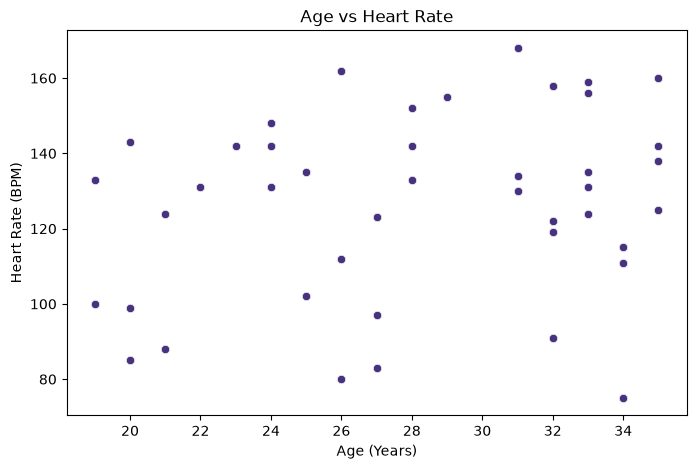

In [253]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=merged_df,
    x='Age',
    y='heart_rate'
)

plt.title('Age vs Heart Rate')
plt.xlabel('Age (Years)')
plt.ylabel('Heart Rate (BPM)')
plt.show()

### Is there a clear relationship between age and heart rate?
* The scatter plot shows no clear linear relationship between age and heart rate, as the data points are widely scattered.

## Multivariate Analysis

### Average Heart Rate by Activity and Fitness Level

In [254]:
# Calculate average heart rate for each fitness level within each activity.

merged_df = merged_df.merge(
    subject_df[['Subject_ID', 'Fitness_Level']],
    on='Subject_ID',
    how='left'
)

In [255]:
fitness_activity = merged_df.groupby(['activity_label', 'Fitness_Level'])['heart_rate'].mean().reset_index()

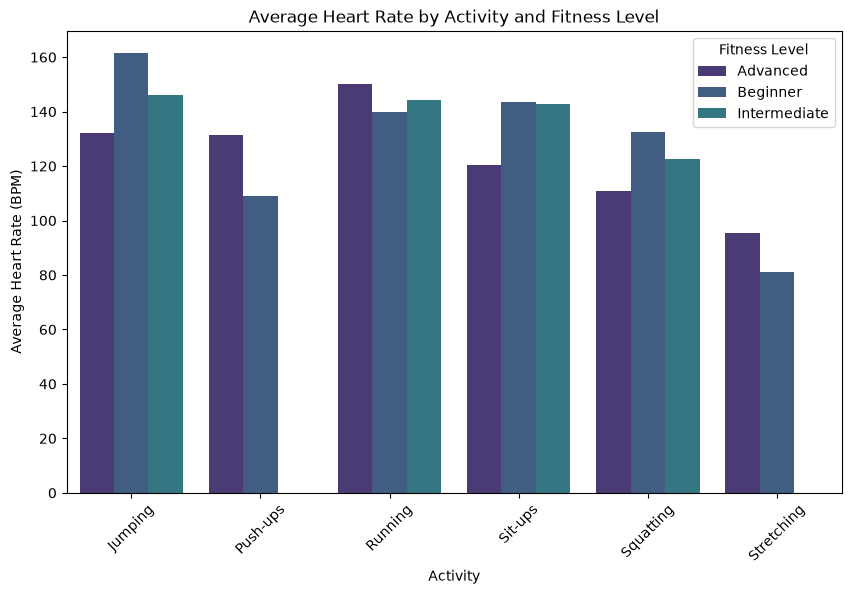

In [256]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=fitness_activity,
    x='activity_label',
    y='heart_rate',
    hue='Fitness_Level',
    errorbar=None
)

plt.title('Average Heart Rate by Activity and Fitness Level')
plt.xlabel('Activity')
plt.ylabel('Average Heart Rate (BPM)')
plt.legend(title='Fitness Level')
plt.xticks(rotation=45)
plt.show()

#### Does average heart rate vary depending on activity type and fitness level?
* Beginner participants recorded higher average heart rates in Jumping, Sit-ups, and Squatting.
* Advanced participants recorded higher average heart rates in Push-ups, Running, and Stretching.
* The relationship between fitness level and heart rate varied across activities.

 ## Average Heart Rate by Age Group and Gender

In [257]:
merged_df['Age_Group'] = pd.cut(
    merged_df['Age'],
    bins=[0, 25, 35],
    labels=['Young', 'Adult']
)

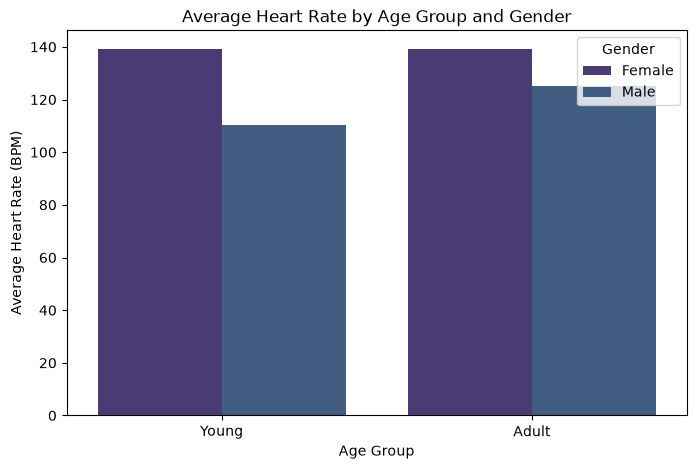

In [258]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=merged_df,
    x='Age_Group',
    y='heart_rate',
    hue='Gender',
    errorbar=None
)

plt.title('Average Heart Rate by Age Group and Gender')
plt.xlabel('Age Group')
plt.ylabel('Average Heart Rate (BPM)')
plt.show()

* Female participants showed a higher average heart rate than male participants across both age groups.

## Average Heart Rate by Activity and Gender

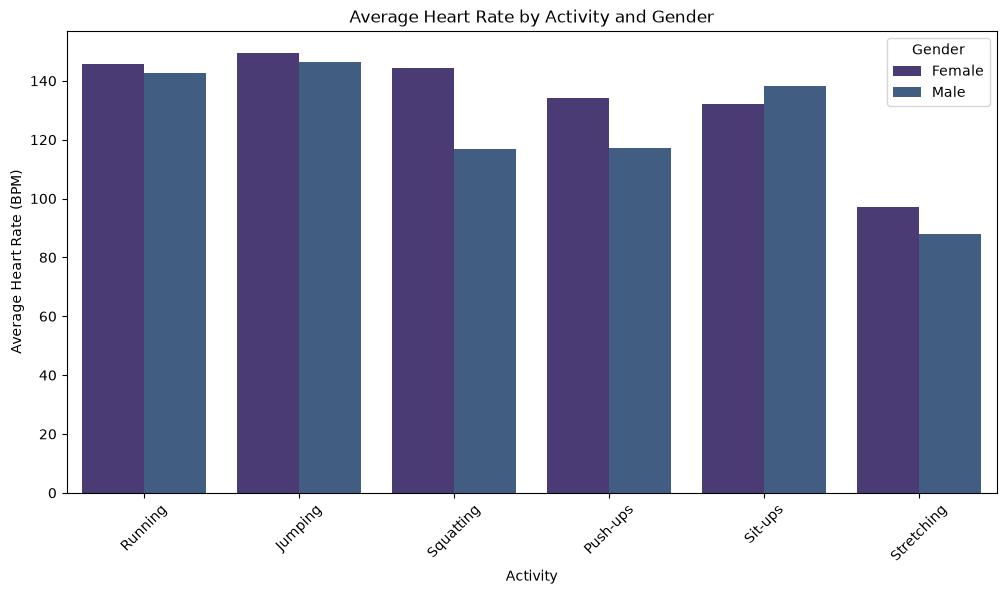

In [259]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=merged_df,
    x='activity_label',
    y='heart_rate',
    hue='Gender',
    errorbar=None
)

plt.title('Average Heart Rate by Activity and Gender')
plt.xlabel('Activity')
plt.ylabel('Average Heart Rate (BPM)')
plt.legend(title='Gender')
plt.xticks(rotation=45)
plt.show()

### Does the difference in heart rate between genders remain across activities?
* Female participants showed a higher average heart rate than male participants across all activities except Sit-ups, where males recorded a higher average heart rate.

## Overall EDA Findings

The exploratory data analysis revealed several important patterns in the dataset:

1. The dataset contains six different physical activities with relatively balanced numbers of records.

2. Heart rate varies across activities, with Jumping showing the highest median heart rate and Stretching showing the lowest.

3. Several accelerometer and gyroscope features showed strong positive correlations, indicating similarities in the information captured by some sensor measurements.

4. Heart rate showed weak correlations with most movement sensor features, suggesting that it provides additional information about physical activity.

5. Wrist and waist sensor measurements showed noticeable differences across activities, indicating that movement patterns vary depending on the exercise performed.

6. Female participants generally recorded higher average heart rates than male participants across most activities, except Sit-ups.

7. The relationship between fitness level and heart rate varied depending on the activity performed.

8. No clear linear relationship was observed between age or BMI and average heart rate in the analyzed participants.
9. Gender and fitness-level differences are descriptive only and do not establish causal effects on heart rate.


## 6.Data Preparation

In [260]:
# Prepare features and target.
X = sensor_df.drop(columns=['timestamp', 'subject_id', 'activity_label'])

y = sensor_df['activity_label']

In [261]:
# Check subjects in each activity.
sensor_df.groupby('activity_label')['subject_id'].unique()

activity_label
Jumping            [9, 10, 11, 12, 13, 14, 15]
Push-ups          [23, 24, 25, 26, 27, 28, 29]
Running                  [2, 3, 4, 5, 6, 7, 8]
Sit-ups           [30, 31, 32, 33, 34, 35, 36]
Squatting         [16, 17, 18, 19, 20, 21, 22]
Stretching    [37, 38, 39, 40, 41, 42, 43, 44]
Name: subject_id, dtype: object

In [262]:
''' Select one subject from each activity.
test_subject= sensor_df.groupby('activity_label')['subject_id'].first().tolist()'''
# Select two subjects from each activity
test_subject = sensor_df.groupby('activity_label')['subject_id'].unique().apply(lambda x: [int(i) for i in x[:2]]).explode().tolist()
test_subject


[9, 10, 23, 24, 2, 3, 30, 31, 16, 17, 37, 38]

* Use a 70/30 split instead of the standard 80/20 split, as the standard split did not ensure enough subjects from each activity in the test set.

In [263]:

# Split data by subjects.
test_id = sensor_df['subject_id'].isin(test_subject)

X_train = X[test_id == False]
X_test = X[test_id == True]

y_train = y[test_id==False]
y_test = y[test_id==True]



In [264]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:")
print(y_train.value_counts())

print("\nTesting target:")
print(y_test.value_counts())

Training features: (1400, 13)
Testing features: (600, 13)

Training target:
activity_label
Stretching    253
Running       250
Squatting     234
Sit-ups       232
Jumping       220
Push-ups      211
Name: count, dtype: int64

Testing target:
activity_label
Running       100
Jumping       100
Squatting     100
Push-ups      100
Sit-ups       100
Stretching    100
Name: count, dtype: int64


In [265]:
# Check that training and testing subjects are separate.
train_subjects = set(sensor_df.loc[test_id == False, 'subject_id'])
test_subjects_set = set(sensor_df.loc[test_id == True, 'subject_id'])

print("Shared subjects:", train_subjects.intersection(test_subjects_set))

Shared subjects: set()


In [266]:
# Apply feature scaling.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 7. Model Training – Exercise Classification

In [267]:
# Create and train the model.
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [268]:
# Predict exercise activities.
y_pred = model.predict(X_test_scaled)

In [269]:
# Calculate model accuracy.
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
# Calculate precision.
precision = precision_score(y_test, y_pred, average='weighted')
print("Precision:", precision)
# Calculate recall.
recall = recall_score(y_test, y_pred, average='weighted')
print("Recall:", recall)
# Calculate F1-score.
f1 = f1_score(y_test, y_pred, average='weighted')
print("F1-score:", f1)

Accuracy: 0.8783333333333333
Precision: 0.896204368324393
Recall: 0.8783333333333333
F1-score: 0.8751580015716525


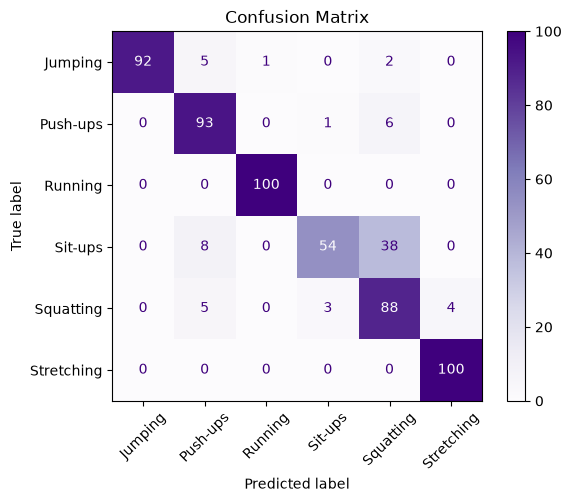

In [270]:


# Plot confusion matrix.
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap='Purples', xticks_rotation=45)

plt.title('Confusion Matrix')
plt.show()

* The Logistic Regression model achieved 87.83% accuracy, demonstrating good overall performance. However, it showed some difficulty distinguishing between Sit-ups and Squatting.



## 8.Effort Level Estimation

* Effort level is calculated from heart rate relative to the maximum heart rate (220 − Age).
* Low: below 60%, Moderate: 60–75%, High: above 75%.

In [271]:
# Create the Effort_Level target
effort_df = sensor_df.merge(
    subject_df[['Subject_ID', 'Age']],
    left_on='subject_id', right_on='Subject_ID', how='inner'
)

effort_df['hr_ratio'] = effort_df['heart_rate'] / (220 - effort_df['Age'])
effort_df['Effort_Level'] = pd.cut(
    effort_df['hr_ratio'],
    bins=[0, 0.60, 0.75, np.inf],
    labels=['Low', 'Moderate', 'High']
)

print(effort_df['Effort_Level'].value_counts())
pd.crosstab(effort_df['activity_label'], effort_df['Effort_Level'])

Effort_Level
Moderate    1011
Low          553
High         436
Name: count, dtype: int64


Effort_Level,Low,Moderate,High
activity_label,,,
Jumping,0,150,170
Push-ups,100,211,0
Running,0,200,150
Sit-ups,0,250,82
Squatting,100,200,34
Stretching,353,0,0


In [272]:
# Binary target: keep only Low and High, drop Moderate
effort_df = effort_df[effort_df['Effort_Level'] != 'Moderate'].copy()
effort_df['Effort_Level'] = effort_df['Effort_Level'].astype(str)

* Moderate was dropped (about half of the data, and the three-class models performed poorly), so the problem is Low vs High.

In [273]:
pd.crosstab(effort_df['activity_label'], effort_df['Effort_Level'])

Effort_Level,High,Low
activity_label,,
Jumping,170,0
Push-ups,0,100
Running,150,0
Sit-ups,82,0
Squatting,34,100
Stretching,0,353


* Jumping, Running and Sit-ups are all High, Push-ups and Stretching are all Low, and only Squatting is mixed.

In [274]:
# Imports for the effort-level experiments
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score


# Features (no heart_rate, no Age)
sensor_cols = [c for c in sensor_df.columns if c.startswith(('wrist_', 'waist_'))]
y_eff = effort_df['Effort_Level']
groups = effort_df['subject_id']
# Stratified by Effort_Level and grouped by subject
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)




In [275]:
print("NaN in y:", y_eff.isna().sum())
print("NaN in sensors:", effort_df[sensor_cols].isna().sum().sum())
print("Suspicious cols:", [c for c in sensor_cols if any(k in c.lower() for k in ('heart', 'hr', 'age'))])
print(y_eff.value_counts())

NaN in y: 0
NaN in sensors: 0
Suspicious cols: []
Effort_Level
Low     553
High    436
Name: count, dtype: int64



All three experiments use the same model (Logistic Regression, `class_weight='balanced'`) and the same `GroupKFold` split by subject, so the comparison is fair. Only the input features change:

| Experiment | Features | Purpose |
|---|---|---|
| A | `heart_rate` + `Age` | Upper bound / sanity check. These are the exact inputs used to build the    label, so this is not a deployable model. |
| B | Movement sensors only | The real ability of movement alone to estimate effort. |
| C | Movement sensors + activity | How much the activity type adds on top of the sensors. |

The activity is one-hot encoded inside the pipeline, so the encoding is fitted only on the training folds.

In [276]:
experiments = {
    'A: HR only':            (['heart_rate', 'Age'], []),
    'B: Sensors only':       (sensor_cols, []),
    'C: Sensors + Activity': (sensor_cols, ['activity_label']),
}

for name, (num_cols, cat_cols) in experiments.items():
    transformers = [('num', StandardScaler(), num_cols)]
    if cat_cols:
        transformers.append(('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols))

    model_eff = make_pipeline(
        ColumnTransformer(transformers),
        LogisticRegression(max_iter=1000, class_weight='balanced')
    )

    X = effort_df[num_cols + cat_cols]
    scores = cross_val_score(model_eff, X, y_eff, cv=cv, groups=groups, scoring='f1_macro')

    print(name)
    print("Macro-F1:", scores.mean())
    print("Std:", scores.std())
    print()

A: HR only
Macro-F1: 1.0
Std: 0.0

B: Sensors only
Macro-F1: 0.6893548550752127
Std: 0.16556202255459604

C: Sensors + Activity
Macro-F1: 0.9125419274774886
Std: 0.06818541707683648



In [277]:
for i, (tr, te) in enumerate(cv.split(effort_df[sensor_cols], y_eff, groups), 1):
    fold = effort_df.iloc[te]
    print(f"Fold {i}: {fold['subject_id'].nunique()} subjects")
    print(fold.groupby('activity_label')['subject_id'].nunique().to_dict())
    print(fold['Effort_Level'].value_counts().to_dict())
    print()

Fold 1: 5 subjects
{'Jumping': 2, 'Squatting': 1, 'Stretching': 2}
{'Low': 150, 'High': 70}

Fold 2: 4 subjects
{'Jumping': 1, 'Push-ups': 1, 'Sit-ups': 1, 'Stretching': 1}
{'High': 100, 'Low': 100}

Fold 3: 4 subjects
{'Jumping': 1, 'Squatting': 1, 'Stretching': 2}
{'Low': 100, 'High': 84}

Fold 4: 5 subjects
{'Running': 1, 'Sit-ups': 1, 'Squatting': 1, 'Stretching': 2}
{'Low': 103, 'High': 82}

Fold 5: 4 subjects
{'Push-ups': 1, 'Running': 2, 'Stretching': 1}
{'High': 100, 'Low': 100}



* **A (heart rate + age):** macro-F1 = ___ (fill in after running). These are the exact inputs used to build the label, so this is an upper bound and a sanity check, not a real result.
* **B (sensors only):** macro-F1 = 0.69 ± 0.17. Movement alone gives only a partial estimate of effort, and the large std shows the result depends on which subjects are in the test fold.
* **C (sensors + activity):** macro-F1 = 0.91 ± 0.07. Adding the activity improves the result clearly, because effort is closely tied to the activity (only Squatting is mixed).
* Only 22 subjects remain after dropping Moderate (4–5 per fold), so these results are indicative and not conclusive.

In [ ]:


import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

eff_num = sensor_cols
eff_cat = ['activity_label']

effort_model = make_pipeline(
    ColumnTransformer([
        ('num', StandardScaler(), eff_num),
        ('cat', OneHotEncoder(handle_unknown='ignore'), eff_cat),
    ]),
    LogisticRegression(max_iter=1000, class_weight='balanced')
).fit(effort_df[eff_num + eff_cat], y_eff)

joblib.dump({"model": effort_model, "features": eff_num + eff_cat},
            "effort_model.pkl")

In [ ]:
import os
print(os.getcwd())
print([f for f in os.listdir() if f.endswith(".pkl")])

In [ ]:
b = joblib.load("effort_model.pkl")
print(b["model"].named_steps.keys())
print(b["features"])

## 9. Key Findings

### Patterns
* The activities are almost balanced (about 310–355 records each).
* Accelerometer readings and gyroscope X/Y are bimodal: a large group of low values and a smaller group of high values, which matches the different activities.
* Heart rate has several peaks and clearly separates the activities: median about 152 BPM for Jumping and 143 for Running, down to about 87 for Stretching.
* Jumping has the highest accelerometer values (X and Y) and Running the lowest. Sit-ups has the highest gyroscope values on both sensors.

### Interesting relationships
* Wrist and waist sensors are strongly correlated (about 0.75–0.96), so they carry similar information.
* Heart rate has weak correlations with all movement sensors (below 0.2). It adds information that movement alone does not give.
* Effort level is closely tied to the activity: Jumping, Running and Sit-ups are all High, Push-ups and Stretching are all Low, and only Squatting is mixed.
* Female participants had a higher average heart rate than males (about 20 BPM), except in Sit-ups. Fitness level also behaved differently from one activity to another.
* No clear linear relationship between age or BMI and heart rate.
* Each participant performed only one activity, so differences between activities are mixed with differences between people (gender, fitness level), and group comparisons are descriptive only.

### Outliers
* Wrist accelerometer: a few upper outliers in X and several in Y.
* Wrist and waist gyroscope Z: outliers on both ends.
* No outliers in the other sensor features, heart rate, age, weight, height or BMI.
* Outliers were kept, since they may reflect real movements of the activities.

### Key takeaways
* Movement sensors identify the exercise well (87.83% accuracy), with Sit-ups the weakest activity, often confused with Squatting.
* Heart rate is what separates effort levels, and movement alone gives only a partial estimate of it (macro-F1 about 0.69, and 0.94 when the activity is known).
* The small number of participants and the single activity per participant limit how far the results generalize.